In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import IPython
import os
import time
import re
import json
from io import StringIO
import gzip
plt.rcParams.update({'font.size': 16})
import pickle
from copy import deepcopy
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from pearlsim.ml_utilities import standardize, unstandardize, add_computed_features, \
    add_feature_noise, exclude_features, add_computed_targets
import pearlsim.lstm
from pearlsim.lstm import LSTM_predictor
from importlib import reload  # Python 3.4+
import keras
import tensorflow as tf



2025-12-18 23:45:03.087396: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-18 23:45:03.089012: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-12-18 23:45:03.092015: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-12-18 23:45:03.101380: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-12-18 23:45:03.117390: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been 

In [2]:
num_cores = 10
threads = num_cores*2
tf.config.threading.set_intra_op_parallelism_threads(threads)
tf.config.threading.set_inter_op_parallelism_threads(threads)

# Data Setup
In this section, the processed operation sequences that have been run by PEARLSim/Serpent are read, restructured into LSTM compatible samples, and divided into training/testing/validation data.

In [3]:
# Feature Configuration Options


# Mean Average Percent Error to add to each dependent feature to simulate
# measurement noise
noise_dict = {
    "R1_avg_FIMA_last_pass":0.1,
    "R2_avg_FIMA_last_pass":0.1,
    "R3_avg_FIMA_last_pass":0.1,
    "R4_avg_FIMA_last_pass":0.1,
    'burnup_bin1_count': 0.05,
    'burnup_bin2_count': 0.05,
    'burnup_bin3_count': 0.05,
    'burnup_bin4_count': 0.05,
    'burnup_bin5_count': 0.05,
    'burnup_bin6_count': 0.05,
    'burnup_bin7_count': 0.05,
    'burnup_bin8_count': 0.05,
    'burnup_bin9_count': 0.05,
    'num_discarded': 0.05,
    'avg_FIMA':0.025
}


# Variable name to human-readable plot label conversion table
feature_rename_key = {'power':"Power", 
                  'burnup_step':"Burnup Step", 
                  'graphite_insertion_fraction':"Fuel Insertion Fraction",
                  'control_rod_position':"Control Rod Insertion",
                  'fima_discharge_threshold': "Discharge Threshold",
                  'R1_avg_FIMA_last_pass':"R1 Last Pass BU",
                  'R2_avg_FIMA_last_pass':"R2 Last Pass BU",
                  'R3_avg_FIMA_last_pass':"R3 Last Pass BU",
                  'R4_avg_FIMA_last_pass':"R4 Last Pass BU",
                  'burnup_bin1_count': "BU Bin 1",
                  'burnup_bin2_count': "BU Bin 2",
                  'burnup_bin3_count': "BU Bin 3",
                  'burnup_bin4_count': "BU Bin 4",
                  'burnup_bin5_count': "BU Bin 5",
                  'burnup_bin6_count': "BU Bin 6",
                  'burnup_bin7_count': "BU Bin 7",
                  'burnup_bin8_count': "BU Bin 8",
                  'burnup_bin9_count': "BU Bin 9",
                  'avg_FIMA': "Avg. Discharge BU", 
                  'num_discarded': "# Discarded",
                  'average_power_per_pebble': "Avg. Power/pebble",
                   "reactivity": "Reactivity",
                   "power_pca0": "Power PC 1",
                   "power_pca1": "Power PC 2",
                   "power_pca2": "Power PC 3",
                   "power_pca3": "Power PC 4",
                   "power_pca4": "Power PC 5",
                   "flux_pca0": "Flux PC 1",
                   "flux_pca1": "Flux PC 2",
                   "flux_pca2": "Flux PC 3",
                   "flux_pca3": "Flux PC 4",
                   "flux_pca4": "Flux PC 5"}


# 
FEATURES_TO_DROP = []

In [4]:
# Data configuration
# The sequences to look for processed data for are listed here and are stored in the directory.
# (i.e. "gFHR_sequence" requires "gFHR_sequence1_inputs.csv.gz" and "gFHR_sequence1_outputs.csv.gz") 

# The gather_.py script in the root directory can be used to extract results from the raw 
# Serpent files if this list is to be extended.

directory = "sequence_data"
sequence_file_base_list = ["gFHR_sequence", 
                           "gFHR_sequence2", 
                           "gFHR_sequence3", 
                           "gFHR_sequence4", 
                           "gFHR_sequence5",
                           "gFHR_sequence6",
                            ####"gFHR_sequence7",
                            "gFHR_sequence8",
                            "gFHR_sequence9",
                            "gFHR_sequence10",
                            "gFHR_sequence11",
                            "gFHR_sequence12",
                            "gFHR_sequence13",
                            "gFHR_sequence14",
                            "gFHR_forecast_base",
                            "gFHR_random_1",
                            "gFHR_random_2",
                            "gFHR_random_3",
                            "gFHR_random_4",
                            "gFHR_random_5",
                            "gFHR_random_6",
                            "gFHR_random_7",
                            "gFHR_random_8",
                            "gFHR_random_9",
                            "gFHR_random_10",
                            "gFHR_random_11",
                            "gFHR_random_12",
                            "gFHR_random_13",
                            "gFHR_random_14",
                            "gFHR_random_15",
                            #####"gFHR_random_16",
                            "gFHR_random_18",
                            "gFHR_random_19",
                            "gFHR_random_20",
                           "gFHR_automated_1",
                           "gFHR_automated_2_10s",
                           "gFHR_automated_2_40s",
                           "gFHR_automated_2_100s",
                           "gFHR_automated_3_10s",
                           "gFHR_automated_3_20s",
                           "gFHR_automated_3_40s",
                           "gFHR_automated_3_100s",
                           "gFHR_automated_4_10s",
                           "gFHR_automated_4_20s",
                           "gFHR_automated_4_40s",
                           "gFHR_automated_4_100s",
                           "gFHR_automated_5_10s",
                           "gFHR_automated_5_20s",
                           "gFHR_automated_5_40s",
                           "gFHR_automated_5_100s",
                           "gFHR_automated_6_10s",
                           "gFHR_automated_6_20s",
                           "gFHR_automated_6_40s",
                           "gFHR_automated_6_100s",
                           "gFHR_automated_extra_1_10s",
                           "gFHR_automated_extra_1_20s",
                           "gFHR_automated_extra_1_40s",
                           "gFHR_automated_extra_1_100s",
                           "gFHR_automated_extra_2_10s",
                           "gFHR_automated_extra_2_20s",
                           "gFHR_automated_extra_2_40s",
                           "gFHR_automated_extra_2_100s",
                           "gFHR_automated_extra_3_10s",
                           "gFHR_automated_extra_3_20s",
                           "gFHR_automated_extra_3_40s",
                           "gFHR_automated_extra_3_100s",
                           "gFHR_automated_extra_4_10s",
                           "gFHR_automated_extra_4_20s",
                           "gFHR_automated_extra_4_40s",
                           "gFHR_automated_extra_4_100s",
                           "gFHR_ascension_graphite_1_80s",
                           "gFHR_ascension_graphite_1_60s",
                           "gFHR_ascension_graphite_1_40s",
                           "gFHR_ascension_power_1_80s",
                           "gFHR_ascension_power_1_60s",
                           "gFHR_ascension_power_1_40s",
                           "gFHR_ascension_graphite_2_80s",
                           "gFHR_ascension_graphite_2_60s",
                           "gFHR_ascension_graphite_2_40s",
                           "gFHR_ascension_power_2_80s",
                           "gFHR_ascension_power_2_60s",
                           "gFHR_ascension_power_2_40s",
                           "gFHR_ascension_graphite_3_80s",
                           "gFHR_ascension_graphite_3_60s",
                           "gFHR_ascension_graphite_3_40s",
                           "gFHR_ascension_power_3_80s",
                           "gFHR_ascension_power_3_60s",
                           "gFHR_ascension_power_3_40s",
                           "gFHR_ascension_graphite_4_80s",
                           "gFHR_ascension_graphite_4_60s",
                           "gFHR_ascension_graphite_4_40s",
                           "gFHR_ascension_power_4_80s",
                           "gFHR_ascension_power_4_60s",
                           "gFHR_ascension_power_4_40s",
                           "gFHR_ascension_graphite_5_80s",
                           "gFHR_ascension_graphite_5_60s",
                           "gFHR_ascension_graphite_5_40s",
                           "gFHR_ascension_power_5_80s",
                           "gFHR_ascension_power_5_60s",
                           "gFHR_ascension_power_5_40s",
                           "gFHR_ascension_graphite_6_80s",
                           "gFHR_ascension_graphite_6_60s",
                           "gFHR_ascension_graphite_6_40s",
                           "gFHR_ascension_power_6_80s",
                           "gFHR_ascension_power_6_60s",
                           "gFHR_ascension_power_6_40s",
                           "gFHR_ascension_graphite_7_80s",
                           "gFHR_ascension_graphite_7_60s",
                           "gFHR_ascension_graphite_7_40s",
                           "gFHR_ascension_power_7_80s",
                           "gFHR_ascension_power_7_60s",
                           "gFHR_ascension_power_7_40s",
                           "gFHR_runin_power_1_80s",
                           "gFHR_runin_graphite_1_80s",
                           "gFHR_runin_power_2_80s",
                           "gFHR_runin_graphite_2_80s",
                           "gFHR_runin_graphite_2_90s",
                           "gFHR_runin_graphite_2_100s",
                           "gFHR_sequence15",
                           "gFHR_runin_power_3_80s",
                           "gFHR_runin_graphite_3_80s_50",
                           "gFHR_runin_graphite_3_60s_75",
                           "gFHR_runin_power_4_60s",
                           "gFHR_runin_power_4_80s",
                           "gFHR_runin_graphite_4_60s_75",
                           "gFHR_runin_graphite_4_80s_50"] 

                           #"gFHR_automated1",
                           #"gFHR_automated2",
                           #"gFHR_automated3",
                           #"gFHR_automated4",
                           #"gFHR_automated5",
                           #"gFHR_automated6",
                           #"gFHR_automated7",
                           #"gFHR_automated8",
                           #"gFHR_automated9",
                           #"gFHR_automated10",
                           #"gFHR_automated11",


In [5]:
# The actual reading of the data files happens here.
input_df_list = []
output_df_list = []

# Set a fixed seed, so that re-running this notebook produces the same results -- at least from start to finish.
SEED = 365



np.random.seed(SEED)

for file_name in sequence_file_base_list:
    print(f"Reading {file_name}")
    input_df = pd.read_csv(f"{directory}/{file_name}_inputs.csv.gz", index_col=0)
    input_df = add_computed_features(input_df)
    input_df = add_feature_noise(input_df, noise_dict)
    input_df = exclude_features(input_df, features_to_drop=FEATURES_TO_DROP)
    input_df_list += [input_df]
    
    output_df = pd.read_csv(f"{directory}/{file_name}_outputs.csv.gz", index_col=0)
    output_df = add_computed_targets(output_df)
    output_df_list += [output_df]
    print(f"Read {len(output_df)} timesteps")


Reading gFHR_sequence
Read 481 timesteps
Reading gFHR_sequence2
Read 341 timesteps
Reading gFHR_sequence3
Read 402 timesteps
Reading gFHR_sequence4
Read 394 timesteps
Reading gFHR_sequence5
Read 358 timesteps
Reading gFHR_sequence6
Read 267 timesteps
Reading gFHR_sequence8
Read 255 timesteps
Reading gFHR_sequence9
Read 334 timesteps
Reading gFHR_sequence10
Read 417 timesteps
Reading gFHR_sequence11
Read 378 timesteps
Reading gFHR_sequence12
Read 253 timesteps
Reading gFHR_sequence13
Read 245 timesteps
Reading gFHR_sequence14
Read 244 timesteps
Reading gFHR_forecast_base
Read 119 timesteps
Reading gFHR_random_1
Read 448 timesteps
Reading gFHR_random_2
Read 451 timesteps
Reading gFHR_random_3
Read 455 timesteps
Reading gFHR_random_4
Read 457 timesteps
Reading gFHR_random_5
Read 450 timesteps
Reading gFHR_random_6
Read 453 timesteps
Reading gFHR_random_7
Read 448 timesteps
Reading gFHR_random_8
Read 448 timesteps
Reading gFHR_random_9
Read 451 timesteps
Reading gFHR_random_10
Read 448 tim

In [6]:
# The input variables listed here are directly controlled by the operator in practice
control_feature_labels =["power","burnup_step","graphite_insertion_fraction", 
                         "fima_discharge_threshold", "control_rod_position"]

In [8]:
# A quick look at the variables
display(input_df.columns)
display(output_df.columns)
display(input_df.iloc[-5:])
display(output_df.iloc[-5:])

Index(['power', 'burnup_step', 'graphite_insertion_fraction',
       'control_rod_position', 'fima_discharge_threshold',
       'fima_discharge_rel_std', 'R1_avg_FIMA_last_pass',
       'R2_avg_FIMA_last_pass', 'R3_avg_FIMA_last_pass',
       'R4_avg_FIMA_last_pass', 'burnup_bin1_count', 'burnup_bin2_count',
       'burnup_bin3_count', 'burnup_bin4_count', 'burnup_bin5_count',
       'burnup_bin6_count', 'burnup_bin7_count', 'burnup_bin8_count',
       'burnup_bin9_count', 'avg_FIMA', 'num_discarded', 'cumulative_time',
       'average_power_per_pebble'],
      dtype='object')

Index(['final_analog_keff', 'final_analog_keff_unc', 'fluxR1Z1E1',
       'fluxR1Z1E2', 'fluxR1Z1E3', 'fluxR1Z2E1', 'fluxR1Z2E2', 'fluxR1Z2E3',
       'fluxR1Z3E1', 'fluxR1Z3E2',
       ...
       'powerR8Z12', 'powerR8Z13', 'powerR8Z14', 'powerR8Z15', 'powerR8Z16',
       'powerR8Z17', 'powerR8Z18', 'powerR8Z19', 'powerR8Z20', 'reactivity'],
      dtype='object', length=643)

,power,burnup_step,graphite_insertion_fraction,control_rod_position,fima_discharge_threshold,fima_discharge_rel_std,R1_avg_FIMA_last_pass,R2_avg_FIMA_last_pass,R3_avg_FIMA_last_pass,R4_avg_FIMA_last_pass,...,burnup_bin4_count,burnup_bin5_count,burnup_bin6_count,burnup_bin7_count,burnup_bin8_count,burnup_bin9_count,avg_FIMA,num_discarded,cumulative_time,average_power_per_pebble
216,280000000.0,6.525,0.401999,369.47,18.63,0.02288,5.174939,3.248744,2.924396,3.275898,...,795.704769,2895.955314,1687.517833,2461.349765,3257.052365,550.718868,13.247011,2087.438903,1415.925,1907.328409
217,280000000.0,6.525,0.399533,369.47,18.63,0.02288,5.390211,4.629012,4.009741,3.416158,...,793.476769,3293.035245,1934.810790,2358.300007,3245.760851,521.385767,13.261189,1924.277076,1422.450,1899.346253
218,280000000.0,6.525,0.397066,369.47,18.63,0.02288,4.817455,4.633408,3.768588,3.989813,...,848.791937,3036.641006,1700.964687,2409.453035,3039.387281,556.400288,12.812373,2152.235413,1428.975,1891.430628
219,280000000.0,6.525,0.394600,369.47,18.63,0.02288,5.051173,4.698417,3.445418,3.175627,...,846.135468,2997.227106,2176.729543,2286.943510,2747.036198,515.412028,13.066021,2257.620725,1435.500,1883.580708
220,280000000.0,6.525,0.392133,369.47,18.63,0.02288,6.257591,3.597039,3.532300,3.083743,...,872.798380,3734.285763,1657.674053,2564.648046,2781.873135,195.652063,12.433947,1566.321796,1442.025,1875.795676


,final_analog_keff,final_analog_keff_unc,fluxR1Z1E1,fluxR1Z1E2,fluxR1Z1E3,fluxR1Z2E1,fluxR1Z2E2,fluxR1Z2E3,fluxR1Z3E1,fluxR1Z3E2,...,powerR8Z12,powerR8Z13,powerR8Z14,powerR8Z15,powerR8Z16,powerR8Z17,powerR8Z18,powerR8Z19,powerR8Z20,reactivity
216,1.03426,0.00172,2.969227e+14,8.002155e+13,1.539190e+14,2.811022e+14,1.177101e+14,2.801239e+14,3.091580e+14,1.519956e+14,...,19.102107,16.729330,16.120192,13.350275,12.666282,10.822745,8.609394,7.174550,5.592279,0.033125
217,1.03210,0.00148,2.999821e+14,8.296313e+13,1.569179e+14,2.817102e+14,1.198655e+14,2.888382e+14,3.095649e+14,1.494471e+14,...,18.955823,17.377552,15.908309,14.635635,13.353361,10.224556,9.228142,7.512890,6.288444,0.031102
218,1.02849,0.00173,2.938861e+14,8.177205e+13,1.574024e+14,2.792645e+14,1.213821e+14,2.881330e+14,3.087912e+14,1.541842e+14,...,19.255706,16.739844,14.998946,13.613244,12.014174,11.290706,9.146955,7.463942,5.933545,0.027701
219,1.02820,0.00140,2.996061e+14,8.366301e+13,1.585967e+14,2.815708e+14,1.229844e+14,2.954427e+14,3.153100e+14,1.575944e+14,...,18.408057,16.713558,15.657340,13.978384,12.528454,10.496336,9.406404,7.593815,6.448237,0.027427
220,1.02504,0.00161,2.922804e+14,8.106223e+13,1.528025e+14,2.762268e+14,1.178233e+14,2.820599e+14,3.040552e+14,1.541785e+14,...,18.205316,16.830700,15.708768,14.427180,13.056107,11.678977,10.141745,7.595061,6.580384,0.024428


In [9]:
# This function is used to convert tabular time series data into 3D sequences
# and perform the test train split

def split_up_sequence(features, targets, train_split, test_split, val_split, window, control_feature_labels, seed=SEED):
    length, num_features = features.shape
    _, num_targets = targets.shape
    num_data = length-1
    num_samples = num_data - window
    training_size = int(num_samples*train_split)
    val_size = max([1,int(num_samples*val_split)])
    testing_size = max([1,int(num_samples*test_split)])
    data_indices = np.arange(window, num_data)
    np.random.shuffle(data_indices)
    training_indices = data_indices[0:training_size]
    testing_indices = data_indices[training_size+1:training_size+testing_size+1]
    
    val_indices = data_indices[training_size+testing_size+1:training_size+testing_size+val_size+1]
    
    training_data_list = []
    training_target_list = []
    testing_data_list = []
    testing_target_list = []
    val_data_list = []
    val_target_list = []
    for index in training_indices:
        training_data_list += [features.iloc[index-window:index].to_numpy().reshape(1, window, num_features)]
        #step_target = [targets.iloc[index]]
        #step_target += [features.iloc[index+1]]
        training_target_list += [pd.concat([targets.iloc[index], features.iloc[index+1].drop(columns=control_feature_labels)])]
    for index in testing_indices:
        testing_data_list += [features.iloc[index-window:index].to_numpy().reshape(1, window, num_features)]
        testing_target_list += [pd.concat([targets.iloc[index], features.iloc[index+1].drop(columns=control_feature_labels)])]
    for index in val_indices:
        val_data_list += [features.iloc[index-window:index].to_numpy().reshape(1, window, num_features)]
        val_target_list += [pd.concat([targets.iloc[index], features.iloc[index+1].drop(columns=control_feature_labels)])]

    data = {}
    data["training_features"] = np.concatenate(training_data_list)
    data["testing_features"] = np.concatenate(testing_data_list)
    data["validation_features"] = np.concatenate(val_data_list)
    data["training_target"] = pd.DataFrame(training_target_list)
    data["testing_target"] = pd.DataFrame(testing_target_list)
    data["validation_target"] = pd.DataFrame(val_target_list)
    return data

In [10]:
# Test train split parameters
window_length = 8   # The number of timesteps to include
data_use_fraction = 1.0  # What fraction of the entire dataset to use (limited to reduce redundancy)
train_split = 0.70 # Fraction of the included data that is used for training
test_split = 0.15 # Fraction of the included data that is used for final testing
val_split = 0.15 # Fraction of the included data that is used for validation / early stopping

train_split = train_split*data_use_fraction
test_split = test_split*data_use_fraction
val_split = val_split*data_use_fraction

In [11]:
# Here the actual splitting function is run, and the data is formatted
# into either 3D Numpy Matrices (features) or tabular Pandas Dataframes (targets)

np.random.seed(SEED+1)

sequenced_data = []
for i in range(len(input_df_list)):
    input_df = input_df_list[i].drop(columns=["cumulative_time","fima_discharge_rel_std"])
    output_df = output_df_list[i]
    sequenced_data += [split_up_sequence(input_df, output_df, train_split, test_split, val_split, 
                                         window_length, control_feature_labels)]
feature_names = input_df.columns.to_list()

grouped_training_features = []
grouped_testing_features = []
grouped_validation_features = []
grouped_training_targets = []
grouped_testing_targets = []
grouped_validation_targets = []
for i in range(len(input_df_list)):
    grouped_training_features += [sequenced_data[i]["training_features"]] 
    grouped_testing_features += [sequenced_data[i]["testing_features"]]
    grouped_validation_features += [sequenced_data[i]["validation_features"]]
    grouped_training_targets += [sequenced_data[i]["training_target"]]
    grouped_testing_targets += [sequenced_data[i]["testing_target"]]
    grouped_validation_targets += [sequenced_data[i]["validation_target"]]

training_data = np.concatenate(grouped_training_features, axis=0)
testing_data = np.concatenate(grouped_testing_features, axis=0)
validation_data = np.concatenate(grouped_validation_features, axis=0)
training_target_no_pca = pd.concat(grouped_training_targets,axis=0).reset_index(drop=True)
testing_target_no_pca = pd.concat(grouped_testing_targets,axis=0).reset_index(drop=True)
validation_target_no_pca = pd.concat(grouped_validation_targets,axis=0).reset_index(drop=True)

In [12]:
flux_columns = []
power_columns = []
for label in training_target_no_pca.columns:
    if "flux" in label:
        flux_columns += [label]

for label in training_target_no_pca.columns:
    if "power" in label and label not in ["power", "average_power_per_pebble"]:
        power_columns += [label]

In [13]:
# Standardize features and calculate the mean / std from just the training data

_, data_mean, data_std = standardize(training_data[:,0,:], axis=0)
training_data_std, _, _ = standardize(training_data, mean=data_mean, std=data_std, axis=2)
testing_data_std, _, _ = standardize(testing_data, mean=data_mean, std=data_std, axis=2)
validation_data_std, _, _ = standardize(validation_data, mean=data_mean, std=data_std, axis=2)


In [14]:
# Standardize targets and calculate the mean / std from just the training data

training_target_std_no_pca, target_mean, target_std = standardize(training_target_no_pca, axis=0)
testing_target_std_no_pca, _, _ = standardize(testing_target_no_pca, mean=target_mean, std=target_std, axis=0)
validation_target_std_no_pca, _, _ = standardize(validation_target_no_pca, mean=target_mean, std=target_std, axis=0)

training_target = training_target_no_pca.copy()
testing_target = testing_target_no_pca.copy()
validation_target = validation_target_no_pca.copy()
training_target_std = training_target_std_no_pca.copy()
testing_target_std = testing_target_std_no_pca.copy()
validation_target_std = validation_target_std_no_pca.copy()

# Principal Component Analysis / Dimensionality Reduction for Flux/Power
Here, the high-dimensionality flux and power tally meshes from Serpent are decomposed using principal component analysis. The scree plots are used to determine how many components to use -- 5 seemed to be sufficient for capturing most variation in the values.

In [15]:
# Fit principal component transformation to power

# Number of components to use
num_power_pca_components = 5


power_pca = PCA(n_components=num_power_pca_components)
power_pca = power_pca.fit(training_target_std_no_pca[power_columns])

power_pca_headers = [f"power_pca{i}" for i in range(num_power_pca_components)]

In [16]:
# How much variance each component captures
print(power_pca.explained_variance_ratio_)
print(sum(power_pca.explained_variance_ratio_))

[0.70090589 0.2397451  0.03431469 0.00906044 0.00533822]
0.9893643405844426


In [17]:
# Apply PCA transformation for power to each of the target datasets

training_power_pca_values = power_pca.transform(training_target_std_no_pca[power_columns])
testing_power_pca_values = power_pca.transform(testing_target_std_no_pca[power_columns])
validation_power_pca_values = power_pca.transform(validation_target_std_no_pca[power_columns])

training_power_pca_values = pd.DataFrame(training_power_pca_values, columns = power_pca_headers)
testing_power_pca_values = pd.DataFrame(testing_power_pca_values, columns = power_pca_headers)
validation_power_pca_values = pd.DataFrame(validation_power_pca_values, columns = power_pca_headers)


training_target.drop(columns=power_columns, errors="ignore", inplace=True)
testing_target.drop(columns=power_columns, errors="ignore", inplace=True)
validation_target.drop(columns=power_columns, errors="ignore", inplace=True)

training_target[power_pca_headers] = training_power_pca_values
testing_target[power_pca_headers] = testing_power_pca_values
validation_target[power_pca_headers] = validation_power_pca_values


In [18]:
# Fit principal component transformation to flux mesh

num_flux_pca_components = 5
flux_pca = PCA(n_components=num_flux_pca_components)
flux_pca = flux_pca.fit(training_target_std_no_pca[flux_columns])

flux_pca_headers = [f"flux_pca{i}" for i in range(num_flux_pca_components)]

In [19]:
# How much variance each component captures
print(flux_pca.explained_variance_ratio_)
print(sum(flux_pca.explained_variance_ratio_))

[0.71206064 0.19106253 0.06510236 0.01885881 0.00423805]
0.9913223915232762


In [20]:
# Apply PCA transformation for flux to each of the target datasets

training_flux_pca_values = flux_pca.transform(training_target_std[flux_columns])
testing_flux_pca_values = flux_pca.transform(testing_target_std[flux_columns])
validation_flux_pca_values = flux_pca.transform(validation_target_std[flux_columns])

training_flux_pca_values = pd.DataFrame(training_flux_pca_values, columns = flux_pca_headers)
testing_flux_pca_values = pd.DataFrame(testing_flux_pca_values, columns = flux_pca_headers)
validation_flux_pca_values = pd.DataFrame(validation_flux_pca_values, columns = flux_pca_headers)

training_target.drop(columns=flux_columns, errors="ignore", inplace=True)
testing_target.drop(columns=flux_columns, errors="ignore", inplace=True)
validation_target.drop(columns=flux_columns, errors="ignore", inplace=True)

training_target[flux_pca_headers] = training_flux_pca_values
testing_target[flux_pca_headers] = testing_flux_pca_values
validation_target[flux_pca_headers] = validation_flux_pca_values

## Scree Plot Generation
Here, the scree plots are used to illustrate the diminishing returns on increasing component numbers. Components with low explanation variance ratios functionally only capture statistical noise, rather than meaningful differences.

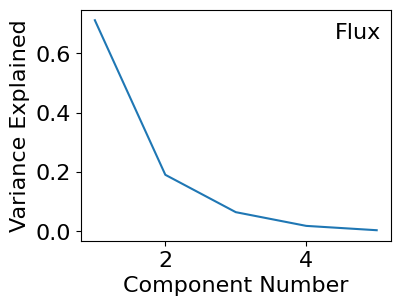

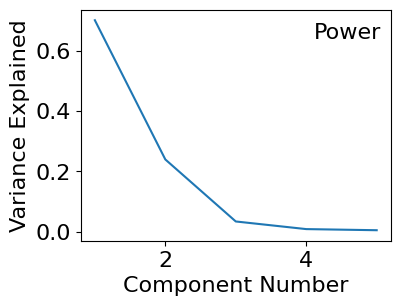

In [21]:
pca_data = {
    "Flux": flux_pca.explained_variance_ratio_,
    "Power": power_pca.explained_variance_ratio_
}

for key in pca_data.keys():
    ratios = pca_data[key]
    num_components = len(ratios)
    fig, ax=  plt.subplots()
    fig.set_figheight(3)
    fig.set_figwidth(4)
    plt.text(0.97, 0.9, key,
     horizontalalignment='right',
     verticalalignment='center',
     transform = ax.transAxes)
    plt.plot(range(1,1+num_components), ratios)
    plt.xlabel("Component Number")
    plt.ylabel("Variance Explained")
    plt.show()
    
    

In [22]:
# Set the mean and standard deviation for the principal component variables, which are
# innately given by standard normal distributions
for label in flux_pca_headers + power_pca_headers:
    target_mean[label] = 0
    target_std[label] = 1

In [23]:
display(training_target[-5:])
display(testing_target[-5:])
display(validation_target[-5:])

,final_analog_keff,final_analog_keff_unc,reactivity,power,burnup_step,graphite_insertion_fraction,control_rod_position,fima_discharge_threshold,R1_avg_FIMA_last_pass,R2_avg_FIMA_last_pass,...,power_pca0,power_pca1,power_pca2,power_pca3,power_pca4,flux_pca0,flux_pca1,flux_pca2,flux_pca3,flux_pca4
14201,0.995684,0.00183,-0.004335,280000000.0,6.525,0.535190,369.47000,18.63,5.317010,5.749143,...,10.862988,-0.732435,-2.310758,-0.014664,0.710023,7.474103,5.107562,-2.295554,-2.199564,-0.023265
14202,0.977426,0.00132,-0.023095,280000000.0,6.525,0.461195,369.47000,18.63,4.744166,4.557242,...,9.990202,0.875325,-2.381009,-0.007809,0.380928,6.580646,3.849528,-3.312612,-2.401248,0.303814
14203,0.878087,0.00195,-0.138839,216722260.0,6.525,0.591920,369.47000,18.63,5.219973,4.163910,...,3.615004,0.522049,-1.725467,-0.083436,-0.151424,4.742340,1.961385,0.073851,-1.859737,0.179843
14204,0.949847,0.00159,-0.052801,162124210.0,6.525,0.688113,369.47000,18.63,5.924736,5.373031,...,-2.365125,2.030981,-2.801511,0.557779,0.123159,-3.763052,-2.779205,1.399429,-2.941129,-0.382025
14205,0.987985,0.00135,-0.012161,64127710.0,6.525,0.860768,178.06282,18.63,2.100600,2.121522,...,-11.045698,-2.075992,-0.183913,-0.303893,0.013599,-13.747029,-1.863948,4.348418,0.432886,-0.273621


,final_analog_keff,final_analog_keff_unc,reactivity,power,burnup_step,graphite_insertion_fraction,control_rod_position,fima_discharge_threshold,R1_avg_FIMA_last_pass,R2_avg_FIMA_last_pass,...,power_pca0,power_pca1,power_pca2,power_pca3,power_pca4,flux_pca0,flux_pca1,flux_pca2,flux_pca3,flux_pca4
3004,0.949985,0.00170,-0.052648,87926860.0,6.525,0.818838,369.47,18.63,5.418476,4.618927,...,-7.324293,-2.876311,-0.228842,-0.323182,0.193327,-8.787862,0.481068,4.624579,0.348676,-0.049522
3005,0.824203,0.00189,-0.213293,153724510.0,6.525,0.702912,369.47,18.63,4.554950,4.128158,...,-4.072339,3.518624,-1.593353,0.360227,-0.075322,-2.579301,-5.177478,1.595124,-2.395443,-0.277670
3006,0.698159,0.00204,-0.432338,139725010.0,6.525,0.727577,369.47,18.63,6.934408,5.941618,...,-3.944282,0.512654,-0.564531,0.241450,-1.052928,1.876570,-1.321009,3.575197,-0.763755,0.028702
3007,0.988663,0.00168,-0.011467,76727260.0,6.525,0.838570,369.47,18.63,5.242758,4.190034,...,-8.490784,-2.735236,-0.214751,-0.205270,0.149631,-10.665671,-0.283304,4.581055,0.387391,-0.102873
3008,0.957013,0.00160,-0.044918,178923610.0,6.525,0.658515,369.47,18.63,5.935149,5.842896,...,1.484986,-2.525573,-0.828186,-0.325240,0.355158,0.216405,3.579273,1.900762,-0.398505,-0.017726


,final_analog_keff,final_analog_keff_unc,reactivity,power,burnup_step,graphite_insertion_fraction,control_rod_position,fima_discharge_threshold,R1_avg_FIMA_last_pass,R2_avg_FIMA_last_pass,...,power_pca0,power_pca1,power_pca2,power_pca3,power_pca4,flux_pca0,flux_pca1,flux_pca2,flux_pca3,flux_pca4
2986,0.978002,0.00168,-0.022493,280000000.0,6.525,0.463662,369.47,18.63,5.711071,4.922319,...,10.094270,0.595609,-2.599033,-0.079138,0.549514,6.825010,4.062196,-3.265444,-2.704861,0.104003
2987,0.964192,0.00166,-0.037138,83727010.0,6.525,0.826237,369.47,18.63,5.400650,4.375718,...,-7.720753,-2.895937,-0.115013,-0.294034,0.142970,-9.494465,0.264351,4.611171,0.472063,-0.049127
2988,0.970002,0.00132,-0.030926,280000000.0,6.525,0.466128,369.47,18.63,4.100652,4.185687,...,9.884082,1.180547,-2.568601,0.031525,0.408270,6.746383,3.404121,-3.337949,-2.814539,0.230608
2989,1.003870,0.00177,0.003855,10000.0,6.525,0.887900,60.25,18.63,0.001008,0.000784,...,-16.379698,-1.812793,0.547948,0.415049,0.000928,-20.134877,-3.872594,4.452426,1.097590,-0.208775
2990,0.944964,0.00169,-0.058241,89326810.0,6.525,0.816371,369.47,18.63,5.018021,3.738060,...,-7.234279,-2.771993,-0.240666,-0.207553,0.189637,-8.639504,0.374933,4.555135,0.297416,-0.065195


In [24]:
output_df[-5:]

,final_analog_keff,final_analog_keff_unc,fluxR1Z1E1,fluxR1Z1E2,fluxR1Z1E3,fluxR1Z2E1,fluxR1Z2E2,fluxR1Z2E3,fluxR1Z3E1,fluxR1Z3E2,...,powerR8Z12,powerR8Z13,powerR8Z14,powerR8Z15,powerR8Z16,powerR8Z17,powerR8Z18,powerR8Z19,powerR8Z20,reactivity
216,1.03426,0.00172,2.969227e+14,8.002155e+13,1.539190e+14,2.811022e+14,1.177101e+14,2.801239e+14,3.091580e+14,1.519956e+14,...,19.102107,16.729330,16.120192,13.350275,12.666282,10.822745,8.609394,7.174550,5.592279,0.033125
217,1.03210,0.00148,2.999821e+14,8.296313e+13,1.569179e+14,2.817102e+14,1.198655e+14,2.888382e+14,3.095649e+14,1.494471e+14,...,18.955823,17.377552,15.908309,14.635635,13.353361,10.224556,9.228142,7.512890,6.288444,0.031102
218,1.02849,0.00173,2.938861e+14,8.177205e+13,1.574024e+14,2.792645e+14,1.213821e+14,2.881330e+14,3.087912e+14,1.541842e+14,...,19.255706,16.739844,14.998946,13.613244,12.014174,11.290706,9.146955,7.463942,5.933545,0.027701
219,1.02820,0.00140,2.996061e+14,8.366301e+13,1.585967e+14,2.815708e+14,1.229844e+14,2.954427e+14,3.153100e+14,1.575944e+14,...,18.408057,16.713558,15.657340,13.978384,12.528454,10.496336,9.406404,7.593815,6.448237,0.027427
220,1.02504,0.00161,2.922804e+14,8.106223e+13,1.528025e+14,2.762268e+14,1.178233e+14,2.820599e+14,3.040552e+14,1.541785e+14,...,18.205316,16.830700,15.708768,14.427180,13.056107,11.678977,10.141745,7.595061,6.580384,0.024428


In [25]:
# You can choose to save or load the training data here, allowing
# to skip the sections above if desired.

# Save/load configuration #######
label = "_no_startup_runin4"
save_processed_data = True
read_processed_data = False
#################################

if save_processed_data:
    np.save(f"training_data/sequence_training_data{label}.npy", training_data_std)
    np.save(f"training_data/sequence_testing_data{label}.npy", testing_data_std)
    
    training_target_std.to_csv(f"training_data/sequence_training_target{label}.csv.gz", header=True)
    testing_target_std.to_csv(f"training_data/sequence_testing_target{label}.csv.gz", header=True)
    
    target_mean.to_csv(f"ml_models/sequence_target_mean{label}.csv", header=True)
    target_std.to_csv(f"ml_models/sequence_target_std{label}.csv", header=True)
    
    np.save(f"training_data/sequence_data_mean{label}.npy", data_mean)
    np.save(f"training_data/sequence_data_std{label}", data_std)

if read_processed_data:
    training_data_std = np.load(f"training_data/sequence_training_data{label}.npy")
    testing_data_std = np.load(f"training_data/sequence_testing_data{label}.npy")
    data_mean = np.load(f"training_data/sequence_data_mean{label}.npy")
    data_std = np.load(f"training_data/sequence_data_std{label}")
    
    training_target_std = pd.read_csv(f"training_data/sequence_training_target{label}.csv.gz")
    testing_target_std = pd.read_csv(f"training_data/sequence_testing_target{label}.csv.gz")
    target_mean = pd.read_csv(f"ml_models/sequence_target_mean{label}.csv")
    target_std = pd.read_csv(f"ml_models/sequence_target_std{label}.csv")

# Model Training
Here, the LSTM is actually trained.

In [26]:
# You can use this to reimport the LSTM module from PEARLSim for quick changes to the code

do_reimports = True

if do_reimports:
    import pearlsim.lstm
    reload(pearlsim.lstm)
    from pearlsim.lstm import LSTM_predictor


In [27]:
predict_labels = ["reactivity"] + power_pca_headers + flux_pca_headers
dependent_input_labels = ["avg_FIMA", "R1_avg_FIMA_last_pass", 
                          "R2_avg_FIMA_last_pass", "R3_avg_FIMA_last_pass", 
                          "R4_avg_FIMA_last_pass", "num_discarded",
                          "burnup_bin1_count", "burnup_bin2_count",
                          "burnup_bin3_count", "burnup_bin4_count",
                          "burnup_bin5_count", "burnup_bin6_count",
                          "burnup_bin7_count", "burnup_bin8_count",
                          "burnup_bin9_count", "avg_FIMA", "average_power_per_pebble"]
model_labels = predict_labels + dependent_input_labels

epochs_keys={}

## Hyperparameter Training
K-folds cross validation is used to find the best layer unit sizes for each parameter here. This process is very time consuming, so it can be skipped and the layer sizes can be set in the next section based on previous results.

In [28]:
# Configuration
do_hyper_parameter_tuning = False
k = 5  # Number of folds
results = {}
if do_hyper_parameter_tuning:
    np.random.seed(SEED)
    
    fold_size_training = len(training_data) // k
    fold_size_testing = len(testing_data) // k
    fold_size_validation = len(validation_data) // k
    
    training_shuffled_indices = np.random.permutation(np.arange(len(training_data)))
    testing_shuffled_indices = np.random.permutation(np.arange(len(testing_data)))
    validation_shuffled_indices = np.random.permutation(np.arange(len(validation_data)))
    
    training_folds = []
    testing_folds = []
    validation_folds = []
    
    for i in range(k):
        start = i * fold_size_training
        end = (i + 1) * fold_size_training if (i < k - 1) else len(training_data)
        training_folds.append(training_shuffled_indices[start:end])
    
        start = i * fold_size_testing
        end = (i + 1) * fold_size_testing if (i < k - 1) else len(testing_data)
        testing_folds.append(testing_shuffled_indices[start:end])
    
        start = i * fold_size_validation
        end = (i + 1) * fold_size_validation if (i < k - 1) else len(validation_data)
        validation_folds.append(validation_shuffled_indices[start:end])
    
    assert np.all(np.sort(np.concatenate(training_folds)) == np.arange(len(training_data)))
    assert np.all(np.sort(np.concatenate(validation_folds)) == np.arange(len(validation_data)))
    assert np.all(np.sort(np.concatenate(testing_folds)) == np.arange(len(testing_data)))

In [29]:
import time

# Configuration
network_size_options = [[16],[32],[64],[128],[256],
                        [16,4],[32,4],[64,4],[128,4],
                        [16,8],[32,8],[64,8],[128,8],
                        [32,16],[64,16],[128,16],[64,32],[128,32],
                        [128,64], 
                        [256,128], 
                        [256,256],
                        [512,128],
                        [512,256]]
                        
parameters_to_tune = model_labels
hyperparameter_file = f"hyperparameters.txt"

if do_hyper_parameter_tuning:
    keras.utils.set_random_seed(SEED)
    

    
    
    for parameter in parameters_to_tune:
        print(parameter)
        if parameter not in results.keys():
            results[parameter] = {}
        fold_results = []
        for network_size in network_size_options:
            print(f"Network size: {network_size}")
            network_key = str(network_size).replace("[","").replace("]","")
            if network_key in results[parameter].keys():
                continue
            network_size_key = {parameter:network_size}
            for num_fold in range(k):
                print(f"Fold number: {num_fold+1}")
                start_time = time.time()
                lstm = LSTM_predictor(data_mean, data_std, target_mean, target_std)
                history = lstm.train(training_data[training_folds[num_fold]], training_target.iloc[training_folds[num_fold]], 
                                     testing_data[testing_folds[num_fold]], testing_target.iloc[testing_folds[num_fold]], 
                                     validation_data[validation_folds[num_fold]], validation_target.iloc[validation_folds[num_fold]], 
                                     [parameter], list(input_df.columns),
                                     verbose_flag = 0,
                          predict_labels = [parameter], 
                                     epochs_default=500, 
                                     batch_size=32, 
                                     learning_rate=0.01, 
                                     network_size_key=network_size_key,
                                     epochs_key=epochs_keys,
                                     input_dropout=0.0, 
                                     recurrent_dropout=0.1,
                                     recurrent_regularizer="l2"
                                    )
                min_val_loss = np.min( history[parameter].history["val_loss"] )
                print(f"Minimum validation loss: {min_val_loss}")
                test_mse = lstm.mse_scores_test[parameter]
                test_r2 = lstm.r2_scores_test[parameter]
                print(f"R2 for fold {num_fold+1}: {test_r2}")
                print(f"MSE for fold {num_fold+1}: {test_mse}")
                fold_results += [test_mse]
                end_time =time.time()
                print(f"{end_time-start_time}s")
    
            average_mse = np.mean(fold_results)
            print(f"Network size {network_size_key} Avg. MSE: {average_mse}")
            results[parameter][network_key] = average_mse
            #with open(hyperparameter_file, "w") as f:
            #    f.write(str(results))



In [30]:
# Determine the best network size based on lowest MSE and turn it into a dictionary
# formatted to be used by PEARLSim's LSTM object

if do_hyper_parameter_tuning:
    best_networks = {}
    for parameter in results:
        min_MSE = 1E24
        for network_key in results[parameter].keys():
            if results[parameter][network_key] < min_MSE:
                min_MSE = results[parameter][network_key] 
                best_networks[parameter] = network_key
    best_network_sizes = pd.Series(best_networks, name="Best Network Sizes")
    display(best_network_sizes)
    network_size_key = best_networks.copy()
    for key in network_size_key.keys():
        network_size_key[key] = network_size_key[key].split(",")
        for i in range(len(network_size_key[key])):
            network_size_key[key][i] = int(network_size_key[key][i])

## Network Size Configuration
Here, you can set the unit sizes for each network. You can also set numbers of epochs for each parameter, although early stopping based on the validation data is used by default.

In [31]:
network_size_key={'reactivity': [512, 128], #[256, 128]
 'power_pca0': [64],
 'power_pca1': [256, 128],
 'power_pca2': [32],
 'power_pca3': [256, 128],
 'power_pca4': [256, 128],
 'flux_pca0': [256],
 'flux_pca1': [256],
 'flux_pca2': [64, 4],
 'flux_pca3': [256, 128],
 'flux_pca4': [128, 64],
 'avg_FIMA': [256],
 'R1_avg_FIMA_last_pass': [64],
 'R2_avg_FIMA_last_pass': [256],
 'R3_avg_FIMA_last_pass': [64],
 'R4_avg_FIMA_last_pass': [256],
 'num_discarded': [32],
 'burnup_bin1_count': [32],
 'burnup_bin2_count': [128, 64],
 'burnup_bin3_count': [128, 8],
 'burnup_bin4_count': [64],
 'burnup_bin5_count': [256, 128],
 'burnup_bin6_count': [128, 64],
 'burnup_bin7_count': [64, 4],
 'burnup_bin8_count': [256, 128],
 'burnup_bin9_count': [16, 8],
 'average_power_per_pebble': [32, 4]}

In [32]:
table = {}
for key in network_size_key.keys():
    table[key] = str(network_size_key[key])
display(table)
display(pd.Series(table))

{'reactivity': '[512, 128]',
 'power_pca0': '[64]',
 'power_pca1': '[256, 128]',
 'power_pca2': '[32]',
 'power_pca3': '[256, 128]',
 'power_pca4': '[256, 128]',
 'flux_pca0': '[256]',
 'flux_pca1': '[256]',
 'flux_pca2': '[64, 4]',
 'flux_pca3': '[256, 128]',
 'flux_pca4': '[128, 64]',
 'avg_FIMA': '[256]',
 'R1_avg_FIMA_last_pass': '[64]',
 'R2_avg_FIMA_last_pass': '[256]',
 'R3_avg_FIMA_last_pass': '[64]',
 'R4_avg_FIMA_last_pass': '[256]',
 'num_discarded': '[32]',
 'burnup_bin1_count': '[32]',
 'burnup_bin2_count': '[128, 64]',
 'burnup_bin3_count': '[128, 8]',
 'burnup_bin4_count': '[64]',
 'burnup_bin5_count': '[256, 128]',
 'burnup_bin6_count': '[128, 64]',
 'burnup_bin7_count': '[64, 4]',
 'burnup_bin8_count': '[256, 128]',
 'burnup_bin9_count': '[16, 8]',
 'average_power_per_pebble': '[32, 4]'}

reactivity                  [512, 128]
power_pca0                        [64]
power_pca1                  [256, 128]
power_pca2                        [32]
power_pca3                  [256, 128]
power_pca4                  [256, 128]
flux_pca0                        [256]
flux_pca1                        [256]
flux_pca2                      [64, 4]
flux_pca3                   [256, 128]
flux_pca4                    [128, 64]
avg_FIMA                         [256]
R1_avg_FIMA_last_pass             [64]
R2_avg_FIMA_last_pass            [256]
R3_avg_FIMA_last_pass             [64]
R4_avg_FIMA_last_pass            [256]
num_discarded                     [32]
burnup_bin1_count                 [32]
burnup_bin2_count            [128, 64]
burnup_bin3_count             [128, 8]
burnup_bin4_count                 [64]
burnup_bin5_count           [256, 128]
burnup_bin6_count            [128, 64]
burnup_bin7_count              [64, 4]
burnup_bin8_count           [256, 128]
burnup_bin9_count        

## Final model training
Here, the model to be used and assessed is trained using the complete training/testing sets.

In [ ]:
b_do_training = True
b_save_model = True

keras.utils.set_random_seed(SEED)

if b_do_training:
    lstm = LSTM_predictor(data_mean, data_std, target_mean, target_std)
    history = lstm.train(training_data, training_target, testing_data, testing_target, validation_data, validation_target, model_labels, list(input_df.columns),
              predict_labels = predict_labels, 
                         epochs_default=500, 
                         verbose_flag = 0,
                         batch_size=32, 
                         learning_rate=0.01, 
                         network_size_key=network_size_key,
                         epochs_key=epochs_keys,
                         input_dropout=0.0, 
                         recurrent_dropout=0.1,
                         recurrent_regularizer="l2"
                        )
    if b_save_model:
        filename = "ml_models/core_state_lstm.pkl"
        with open(filename, "wb") as f:
            pickle.dump(lstm, f)
        filename="ml_models/training_history.pkl"
        with open(filename, "wb") as f:
            pickle.dump(history, f)
else:
    filename = "ml_models/core_state_lstm.pkl"
    with open(filename, "rb") as f:
        lstm  = pickle.load(f)
        
    filename="ml_models/training_history.pkl"
    with open(filename, "rb") as f:
        history  = pickle.load(f)

2025-12-18 23:48:28.072427: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:266] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


444/444 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
reactivity trained. R^2 test = 0.9906531730305581 (728.29s taken)
444/444 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
power_pca0 trained. R^2 test = 0.9883701048125277 (154.61s taken)
444/444 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
power_pca1 trained. R^2 test = 0.9725741983729186 (459.47s taken)
444/444 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 991us/step
power_pca2 trained. R^2 test = 0.8324963810527631 (92.63s taken)
444/444 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
power_pca3 trained. R^2 test = 0.9464697053159984 (532.52s taken)
444/444 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms

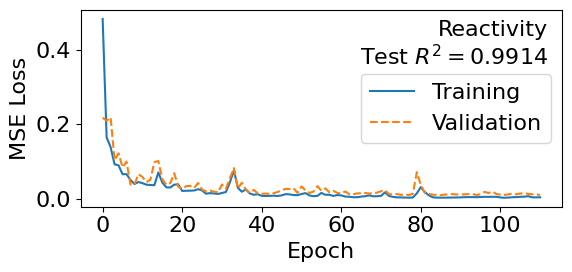

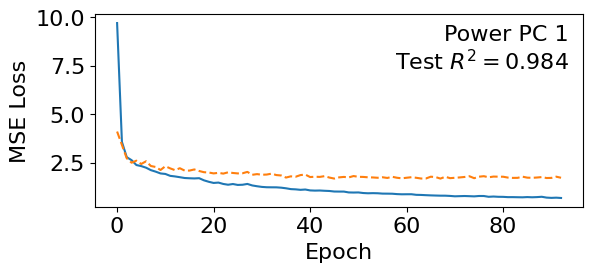

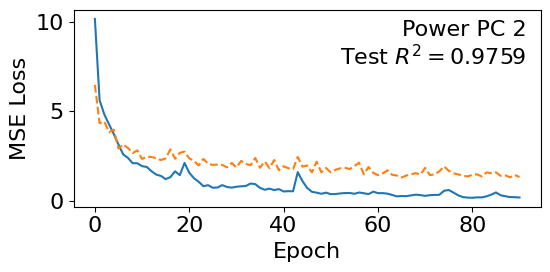

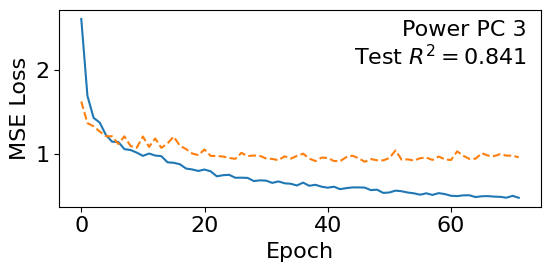

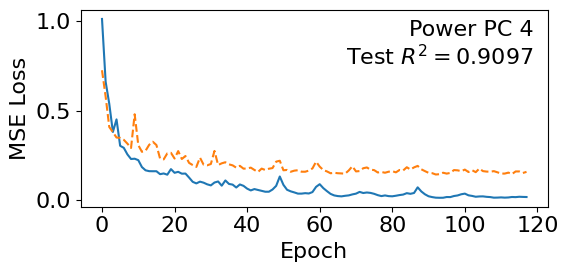

...

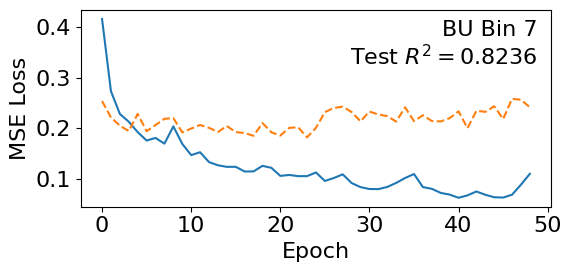

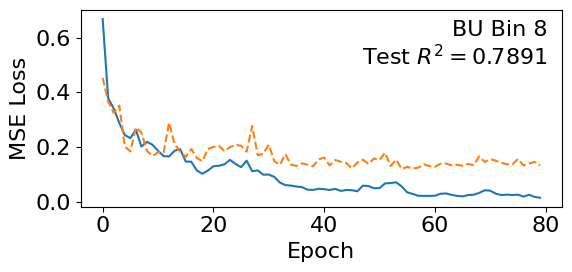

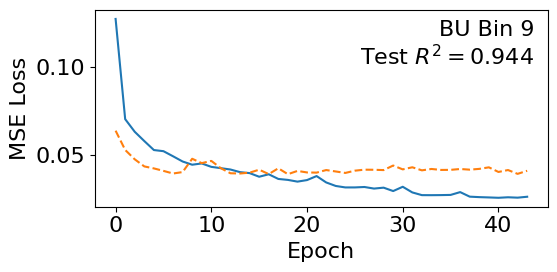

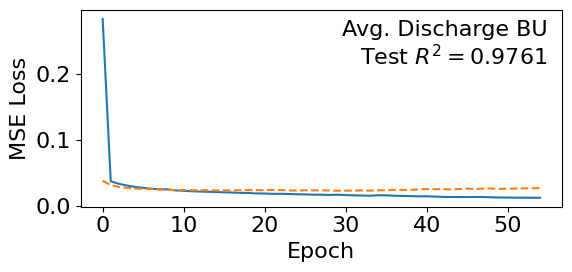

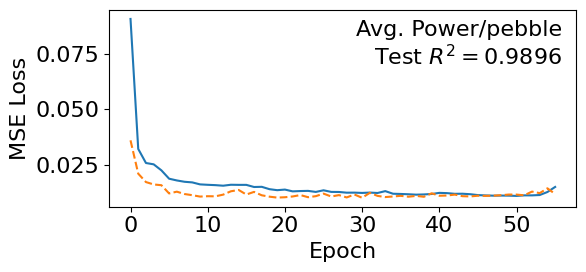

In [32]:
# Here, plots of the training curves are generated from each model's history, and the
# R^2 values for each dataset are also stored.

dict_test_r2 = {}
dict_train_r2 = {}
dict_val_r2 = {}


for parameter_to_plot in model_labels:
    steps = np.arange(len(history[parameter_to_plot].history["loss"]))
    loss = history[parameter_to_plot].history["loss"]
    val_loss = history[parameter_to_plot].history["val_loss"]
    test_r2 = lstm.r2_scores_test[parameter_to_plot]
    train_r2 = lstm.r2_scores_train[parameter_to_plot]
    val_r2 = lstm.r2_scores_val[parameter_to_plot]
    dict_test_r2[parameter_to_plot] = test_r2
    dict_train_r2[parameter_to_plot] = train_r2
    dict_val_r2[parameter_to_plot] = val_r2
    r2_str = r"Test $R^2 = $"+str(round(test_r2,4))
    name = feature_rename_key[parameter_to_plot]
    fig, ax = plt.subplots(figsize=(6,3) )
    plt.plot(steps, loss, label="Training")
    plt.plot(steps, val_loss, "--", label="Validation")
    plt.text(0.97, 0.95, name+"\n"+r2_str, ha='right', verticalalignment='top', transform = ax.transAxes)
    if parameter_to_plot == "reactivity":
        plt.legend(loc="right")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.tight_layout()
    #plt.savefig(f"figures/training_loss/{parameter_to_plot}.png")
    plt.show()


In [33]:
# The R^2 values are displayed in a table format broken into two columns for readability.

r2_table = pd.DataFrame({r"Train $R^{2}$":dict_train_r2,
              r"Test $R^{2}$":dict_test_r2 
              }) 
num_items = int(len(r2_table)/2)

display(r2_table[:num_items])
display(r2_table[num_items:])

,Train $R^{2}$,Test $R^{2}$
reactivity,0.997787,0.991447
power_pca0,0.993117,0.984028
power_pca1,0.995507,0.975853
power_pca2,0.925957,0.841042
power_pca3,0.990882,0.909663
power_pca4,0.960461,0.660790
flux_pca0,0.987742,0.972644
flux_pca1,0.980458,0.949037
flux_pca2,0.987146,0.974187
flux_pca3,0.990365,0.862795


,Train $R^{2}$,Test $R^{2}$
R2_avg_FIMA_last_pass,0.933198,0.894150
R3_avg_FIMA_last_pass,0.924202,0.901915
R4_avg_FIMA_last_pass,0.916616,0.897496
num_discarded,0.846252,0.726498
burnup_bin1_count,0.981341,0.980719
burnup_bin2_count,0.983109,0.842957
burnup_bin3_count,0.934750,0.798997
burnup_bin4_count,0.956934,0.821043
burnup_bin5_count,0.975529,0.829487
burnup_bin6_count,0.945996,0.762681


# Model Performance Assessment
Here, the model's performance is examined from different angles.

## Complete Sequence Prediction
The model's performance on an entire assessment is checked and visualized. The target variables for each step in the selected sequence are predicted, and the overall R^2 is calculated. 

In [36]:
directory = "sequence_data"

fit_test_sequence = "gFHR_sequence7"

fit_test_input_df = add_computed_features(pd.read_csv(f"{directory}/{fit_test_sequence}_inputs.csv.gz", index_col=0)).drop(columns=["fima_discharge_rel_std"])
fit_test_input_time = fit_test_input_df["cumulative_time"]
fit_test_input_df = fit_test_input_df.drop(columns=["cumulative_time"])
fit_test_output_df = add_computed_targets(pd.read_csv(f"{directory}/{fit_test_sequence}_outputs.csv.gz", index_col=0))
fit_test_output_df = pd.concat([fit_test_output_df, 
           fit_test_input_df.iloc[1:].drop(columns=control_feature_labels).reset_index(drop=True)],
          axis=1).fillna(0.0)


y_fit_test_predict = lstm.predict(fit_test_input_df, model_labels)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
10/10 ━━━

In [37]:
# Transform the mesh values into their principal components for the selected sequence

fit_test_output_df_std, _, _ =standardize(fit_test_output_df, target_mean, target_std)
fit_test_output_df_flux_pca = flux_pca.transform(fit_test_output_df_std[flux_columns])
fit_test_output_df_power_pca = power_pca.transform(fit_test_output_df_std[power_columns])
fit_test_output_df[flux_pca_headers] = fit_test_output_df_flux_pca
fit_test_output_df[power_pca_headers] = fit_test_output_df_power_pca

In [38]:
# Definition of a function used for coherently plotting multiple time dependent variables

def make_result_spaghetti_plot(input_plot_structure, predicted_output_df, true_output_df, side_by_sides, sequence_name, window_length, b_show=False):
    
    axis_num = -1
    number_plots = len(input_plot_structure.keys())
    fig, ax = plt.subplots(nrows=number_plots, ncols=1, figsize=(8,8.25),sharex=True,gridspec_kw = {'wspace':0, 'hspace':0})
    
    
    for primary_key in input_plot_structure.keys():
        axis_num += 1
        for secondary_key in input_plot_structure.keys():
            if primary_key in side_by_sides:
                if primary_key == secondary_key:
                    data = input_plot_structure[secondary_key][0]
                    pred_key_name = input_plot_structure[secondary_key][2]
                    parameter_type = input_plot_structure[secondary_key][1]
                    pred_data = predicted_output_df[pred_key_name]/max(np.abs(true_output_df[pred_key_name]))
                    color_to_use = parameter_color_scheme["output"]
                    ax[axis_num].plot(time, data, color="black", zorder=15, linestyle="dashed", linewidth=1.5)
                    ax[axis_num].plot(time[window_length:-1], pred_data, color=color_to_use,zorder=20, linewidth=1.5)
            elif primary_key == secondary_key:
                data = input_plot_structure[secondary_key][0]
                parameter_type = input_plot_structure[secondary_key][1]
                color_to_use = parameter_color_scheme[parameter_type]
                ax[axis_num].plot(time, data, color=color_to_use,zorder=20, linewidth=2.5)
            else:
                if secondary_key not in side_by_sides:
                    data = input_plot_structure[secondary_key][0]
                    ax[axis_num].plot(time, data, color="gray")
        if axis_num != (number_plots-1):
            ax[axis_num].set_xticks([])
        if parameter_type in ("input, dependent_input"):
            ax[axis_num].set_yticks([0,1])
            ax[axis_num].set_ylim(-0.25, 1.4)
        else:
            ax[axis_num].set_yticks([-1,1])
            ax[axis_num].set_ylim(-1.4, 1.4)
        if primary_key in side_by_sides:
            r2 = str(round(r2_score(predicted_output_df[pred_key_name], true_output_df[pred_key_name].iloc[window_length:-1]), 3))
            ax[axis_num].set_ylabel(primary_key+" \n"+r"$r^{2}$: "+r2+"  ", rotation=0, ha="right", va="center")
        else:
            ax[axis_num].set_ylabel(primary_key+" ", rotation=0, ha="right", va="center")
    
    fig.tight_layout()
    plt.savefig(f"figures/{sequence_name}_sequence_accuracy.png")
    if b_show:
        plt.show()

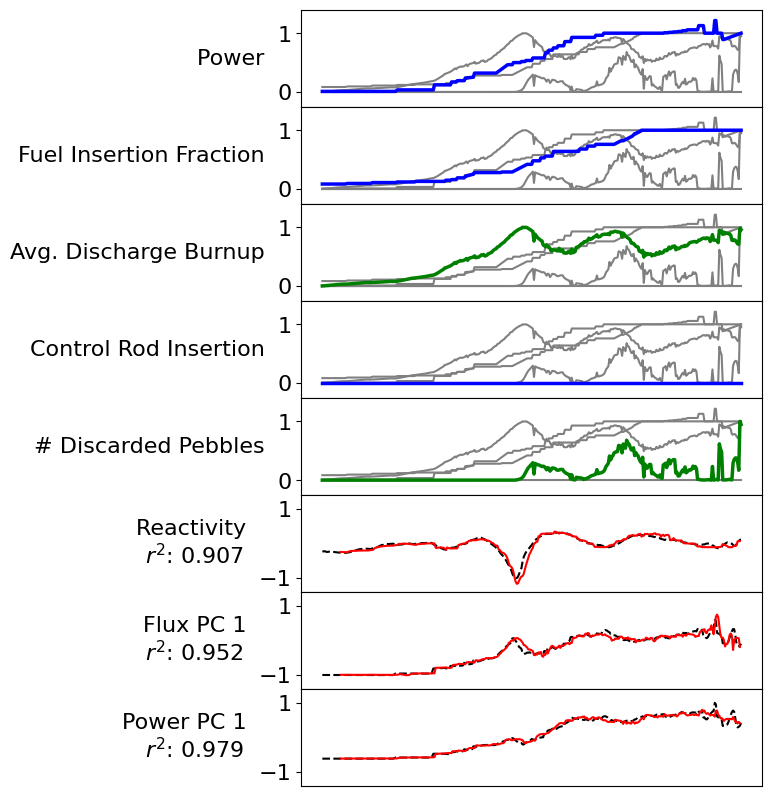

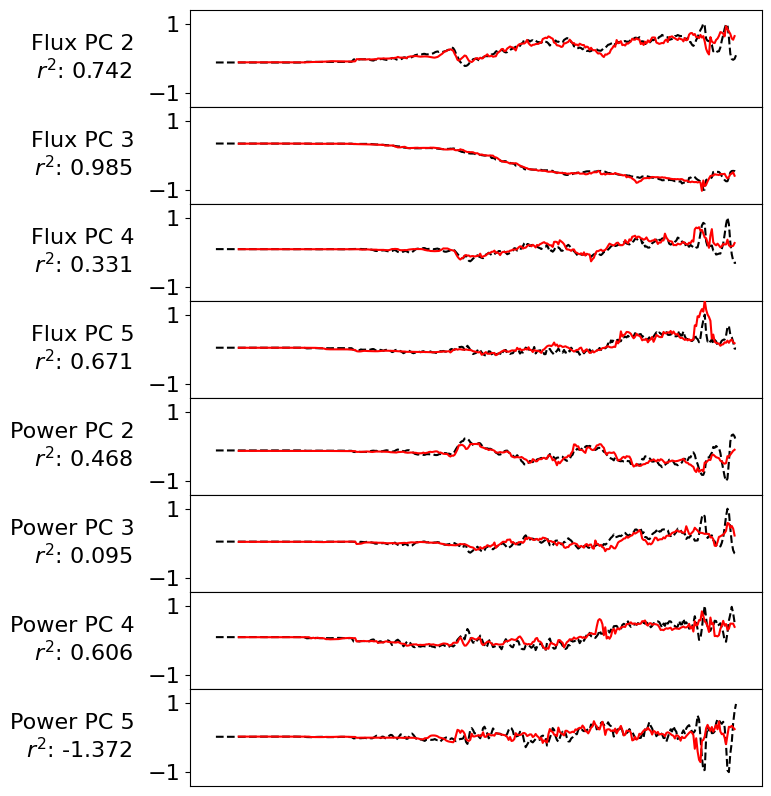

In [39]:
# Here, the predicted and actual values of different parameters are normalized 
# before being plotted using the function above.

file_name =      fit_test_sequence    
input_df =       fit_test_input_df    
output_df =      fit_test_output_df   
output_df_pred = y_fit_test_predict   
time =           fit_test_input_time  

# Preparation of variables

power = input_df["power"]/280e6
fuel_insertion_fraction = 1-input_df["graphite_insertion_fraction"]
discard_threshold = input_df["fima_discharge_threshold"]/18.63
circulation_rate = 6.525/input_df["burnup_step"]
control_rod_insertion = (369.47-input_df["control_rod_position"])/309.47

num_discarded = input_df["num_discarded"]/max(input_df["num_discarded"])

avg_power_per_pebble = input_df["average_power_per_pebble"]/max(input_df["average_power_per_pebble"])



keff = output_df["final_analog_keff"]
reactivity = output_df["reactivity"]/max(np.abs(output_df["reactivity"]))
discharge_burnup = input_df["avg_FIMA"]/max(input_df["avg_FIMA"])
center_last_pass_fima = input_df["R1_avg_FIMA_last_pass"]/max(input_df["R1_avg_FIMA_last_pass"])
flux_pca_vals = output_df[flux_columns]
power_pca_vals = output_df[power_columns]

flux_pca_1 = output_df["flux_pca0"] / max(np.abs(output_df["flux_pca0"]))
flux_pca_2 = output_df["flux_pca1"] / max(np.abs(output_df["flux_pca1"]))
flux_pca_3 = output_df["flux_pca2"] / max(np.abs(output_df["flux_pca2"]))
flux_pca_4 = output_df["flux_pca3"] / max(np.abs(output_df["flux_pca3"]))
flux_pca_5 = output_df["flux_pca4"] / max(np.abs(output_df["flux_pca4"]))

power_pca_1 = output_df["power_pca0"] / max(np.abs(output_df["power_pca0"]))
power_pca_2 = output_df["power_pca1"] / max(np.abs(output_df["power_pca1"]))
power_pca_3 = output_df["power_pca2"] / max(np.abs(output_df["power_pca2"]))
power_pca_4 = output_df["power_pca3"] / max(np.abs(output_df["power_pca3"]))
power_pca_5 = output_df["power_pca4"] / max(np.abs(output_df["power_pca4"]))





plt.rcParams.update({
    "figure.facecolor":  (1.0, 1.0, 1.0, 0.0),  # red   with alpha = 30%
    "axes.facecolor":    (1.0, 1.0, 1.0, 1),  # green with alpha = 50%
    "figure.autolayout": False
})


parameter_color_scheme = {
    "input": "blue",
    "dependent_input": "green",
    "output": "red"
}


input_variables_structure = {
    "Power": (power, "input"),
    "Fuel Insertion Fraction": (fuel_insertion_fraction, "input"),
    "Avg. Discharge Burnup": (discharge_burnup, "dependent_input"),
    "Control Rod Insertion": (control_rod_insertion, "input"),
    "# Discarded Pebbles": (num_discarded, "dependent_input"),
    "Reactivity": (reactivity, "output", "reactivity"),
    "Flux PC 1": (flux_pca_1, "output", "flux_pca0"),
    "Power PC 1": (power_pca_1, "output", "power_pca0"),
}

output_variables_structure = {
    "Flux PC 2": (flux_pca_2, "output", "flux_pca1"),
    "Flux PC 3": (flux_pca_3, "output", "flux_pca2"),
    "Flux PC 4": (flux_pca_4, "output", "flux_pca3"),
    "Flux PC 5": (flux_pca_5, "output", "flux_pca4"),
    "Power PC 2": (power_pca_2, "output", "power_pca1"),
    "Power PC 3": (power_pca_3, "output", "power_pca2"),
    "Power PC 4": (power_pca_4, "output", "power_pca3"),
    "Power PC 5": (power_pca_5, "output", "power_pca4"),
}


side_by_sides = ["Reactivity", "Flux PC 1", "Power PC 1", "Flux PC 2", "Flux PC 3", "Flux PC 4", "Flux PC 5", "Power PC 2", "Power PC 3", "Power PC 4", "Power PC 5"]

b_show = True

make_result_spaghetti_plot(input_variables_structure, output_df_pred, output_df, side_by_sides, "target_accuracy/"+file_name+"_inputs_predictions", window_length, b_show=b_show)
make_result_spaghetti_plot(output_variables_structure, output_df_pred, output_df, side_by_sides, "target_accuracy/"+file_name+"_outputs_predictions", window_length, b_show=b_show)


# Mesh Reconstruction and Comparison
Here, we reconstruct the flux and power meshes using predicted values of principal components and transforming them back to their mesh form. The profile and the cell-wise difference between the predicted and "actual" mesh is then shown as a side by side for different combinations of principal components. In theory, if a principal component is predicted poorly enough that it skews the reconstruction process, you would be able to identify it here. However, if the best reconstruction is achieved using ALL components, then an appropriate number has been selected.

In [40]:
from pearlsim.results_processing import read_core_flux, plot_mesh_from_series, plot_mesh_comparison_from_series

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━━━━━━━━━

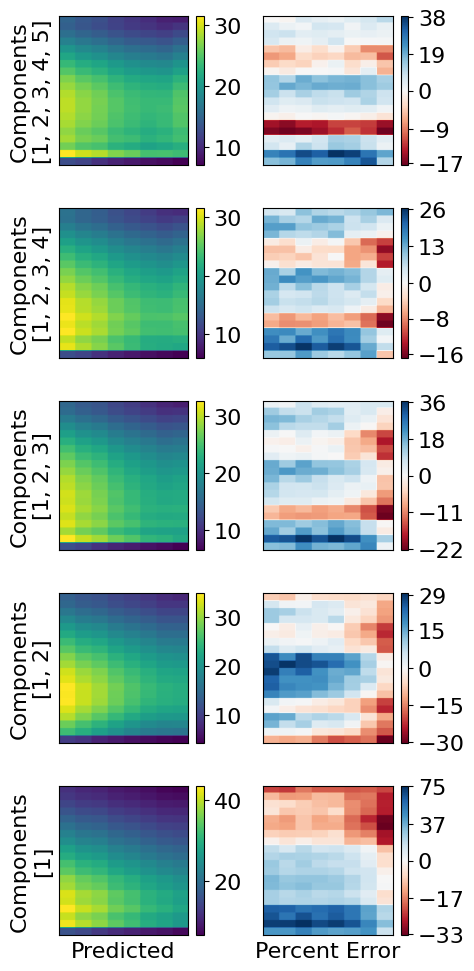

In [41]:
directory = "sequence_data"

mesh_sequence = "gFHR_sequence"

mesh_input_df = add_computed_features(pd.read_csv(f"{directory}/{mesh_sequence}_inputs.csv.gz", index_col=0)).drop(columns=["fima_discharge_rel_std"])
mesh_input_time = mesh_input_df["cumulative_time"]
mesh_input_df = mesh_input_df.drop(columns=["cumulative_time"])
mesh_output_df = add_computed_targets(pd.read_csv(f"{directory}/{mesh_sequence}_outputs.csv.gz", index_col=0))

y_mesh_predict = lstm.predict(mesh_input_df, model_labels)

# Transform the mesh values into their principal components for the selected sequence

#mesh_output_df_std, _, _ =standardize(mesh_output_df, target_mean, target_std)
#mesh_output_df_flux_pca = flux_pca.transform(mesh_output_df[flux_columns])
#mesh_output_df_power_pca = power_pca.transform(mesh_output_df[power_columns])
#mesh_output_df[flux_pca_headers] =  mesh_output_df_flux_pca
#mesh_output_df[power_pca_headers] = mesh_output_df_power_pca



# Mesh plot configuration ###########
mesh_to_plot = "power" # or flux
plot_label = "Power" # This label shows up in the saved figure file only
original_headers = power_columns # or flux_columns
energy_group = None # None for power, 1 2 or 3 for thermal/epithermal/fast

timestep_to_plot = -1 # Last timestep
num_components = 5
num_plots_to_do = 5

# Which components to set to zero
component_to_zero_combos = [ [], [4], [3,4], [2,3,4], [1,2,3,4],]

# The corresponding plot label
component_names = [ "[1, 2, 3, 4, 5]", "[1, 2, 3, 4]", "[1, 2, 3]", "[1, 2]", "[1]", ]
######################################

axis_num = -1

fig, ax = plt.subplots(nrows=num_plots_to_do, ncols=2, figsize=(5,10))



for row_num in range(num_plots_to_do):
    components_to_zero = component_to_zero_combos[row_num]
    component_common_str = component_names[row_num]
    
    label_names = []
    
    if mesh_to_plot == "flux":
        transformer = flux_pca
    else:
        transformer = power_pca
    
    for i in range(num_components):
        label_names += [f"{mesh_to_plot}_pca{i}"]
    
    #output_pca_df = output_df[label_names].copy()
    y_mesh_pca_predict = y_mesh_predict[label_names].copy()
    
    for i in components_to_zero:
    #    output_pca_df[f"{mesh_to_plot}_pca{i}"] = 0.0
        y_mesh_pca_predict[f"{mesh_to_plot}_pca{i}"] = 0.0
    
    #mesh_df_std = transformer.inverse_transform(output_pca_df)
    mesh_pred_df_std = transformer.inverse_transform(y_mesh_pca_predict)
    
    #mesh_df = unstandardize(mesh_df_std, target_mean[original_headers], target_std[original_headers])
    mesh_pred_df = unstandardize(mesh_pred_df_std, target_mean[original_headers], target_std[original_headers])
    
    #mesh_df.columns = original_headers
    mesh_pred_df.columns = original_headers
    
    predicted_series = mesh_pred_df.iloc[timestep_to_plot]
    actual_series = mesh_output_df.iloc[timestep_to_plot][original_headers]
    
    comps_used = num_components-len(components_to_zero)
    
    if energy_group == None:
        mesh_str = "power"
    else:
        mesh_str = f"flux{energy_group}"
    
    #plot_name = "figures/mesh_reconstruction/"+file_name+f"_{mesh_str}_comps{comps_used}_step{timestep_to_plot}"
    
    plot_mesh_comparison_from_series(predicted_series, actual_series, component_common_str, fig, ax, row_num, plot_energy_group=energy_group)

if mesh_str == "power":
    energy_group = 0

ax[row_num, 0].set_xlabel("Predicted")
#ax[row_num, 1].set_xlabel("Actual")
ax[row_num, 1].set_xlabel("Percent Error")
fig_name = f"figures/mesh_reconstruction/{file_name}_{plot_label}_E{energy_group}.png"
plt.tight_layout()
plt.savefig(fig_name)

# Global Feature Importance Plots
Next, the feature importance is calculated for a single sequence. Different sequences may emphasize dif

In [56]:
# Use the LSTM to predict values for ALL sequences
targets_to_compute_importance = ["reactivity", "power_pca0", "flux_pca0", "num_discarded", "avg_FIMA", "burnup_bin9_count", "R3_avg_FIMA_last_pass"] 
feature_imp_shuffled_mse = {}
feature_imp_baseline_mse = {}
output_pred_df_list = []

output_actual_df_list = []

total_num_steps = 0
for seq_i in range(len(input_df_list)):
    sequence_length = len(input_df_list[seq_i])
    total_num_steps += sequence_length
    output_pred_df_list += [lstm.predict(input_df_list[seq_i], model_labels)]
    output_actual_df = output_df_list[seq_i].copy()

    # Outputs are going to need the next values of the corresponding dependent
    # input variables
    output_actual_df = pd.concat([output_actual_df, 
           input_df_list[seq_i].iloc[1:].drop(columns=control_feature_labels).reset_index(drop=True)],
          axis=1).fillna(0.0)

    # Outputted predictions will be principal components so we need
    # to have the transformed values for the actual sequence targets handy
    output_actual_df_std,_,_=standardize(output_actual_df, target_mean, target_std)
    output_actual_df_flux_pca = flux_pca.transform(output_actual_df_std[flux_columns])
    output_actual_df_power_pca = power_pca.transform(output_actual_df_std[power_columns])
    output_actual_df[flux_pca_headers] = output_actual_df_flux_pca
    output_actual_df[power_pca_headers] = output_actual_df_power_pca
    
    output_actual_df_list += [output_actual_df]

# Calculate MSE for each target as a baseline
# Each sequence has to be handled separately
for output_header in targets_to_compute_importance:
    feature_imp_shuffled_mse[output_header] = {}
    feature_imp_baseline_mse[output_header] = 0
    for seq_i in  range(len(input_df_list)):
        sequence_length = len(input_df_list[seq_i])
        y_actual = output_actual_df_list[seq_i][output_header].iloc[window_length:-1]
        y_predicted = output_pred_df_list[seq_i][output_header]
        feature_imp_baseline_mse[output_header] += mean_absolute_error(y_actual, y_predicted) * sequence_length / total_num_steps


# Randomly shuffled the values of one feature at a time
# For all of the targets of interest, calculate the new
# MSE. This is done for all sequences and weighted by length
for feature_header in input_df.columns:
    
    for seq_i in range(len(input_df_list)):
        input_df_shuffled = input_df_list[seq_i].copy()
    
        input_df_shuffled[feature_header] = np.random.permutation(input_df_shuffled[feature_header].values)

        
        y_predicted_shuffled = lstm.predict(input_df_shuffled, model_labels)
       
        for output_header in targets_to_compute_importance:
            y_actual = output_actual_df_list[seq_i][output_header].iloc[window_length:-1]
            weighted_mse = mean_absolute_error(y_actual, y_predicted_shuffled[output_header]) * sequence_length / total_num_steps
            if feature_header in feature_imp_shuffled_mse[output_header].keys():
                feature_imp_shuffled_mse[output_header][feature_header] += weighted_mse
            else:
                feature_imp_shuffled_mse[output_header][feature_header] = weighted_mse
        

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
15/15 ━━━━

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
14/14 ━━━

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
14/14 ━━━━

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
14/14 ━━━

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



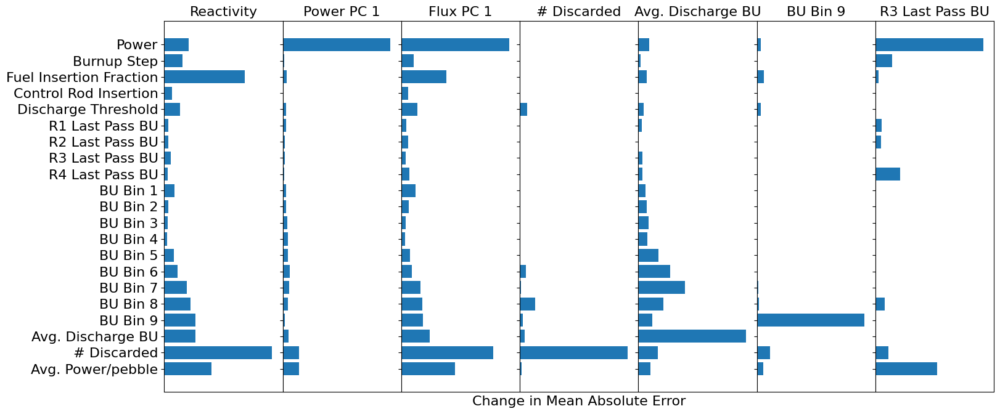

In [60]:

fig, ax = plt.subplots(ncols=7, figsize=(16.5,7), sharey=True,gridspec_kw = {'wspace':0, 'hspace':0})
#fig, ax = plt.subplots(ncols=3, figsize=(8.5,7), sharey=True,gridspec_kw = {'wspace':0, 'hspace':0})



for o in range(len(targets_to_compute_importance )):
    output_header = targets_to_compute_importance[o]
    clean_header = feature_rename_key[output_header]


    
    mse_change_by_feature_series = pd.Series(feature_imp_shuffled_mse[output_header]).rename(feature_rename_key)-feature_imp_baseline_mse[output_header]

    

    y_pos = np.arange(len(mse_change_by_feature_series))
    
    
    ax[o].barh(y_pos, mse_change_by_feature_series.values, align='center')
    ax[o].set_yticks(y_pos, labels=list(mse_change_by_feature_series.index))
   # ax[o].invert_yaxis()  # labels read top-to-bottom
    ax[o].set_title(clean_header, fontdict={"fontsize":16})
    ax[o].set_xlim(0,1.1*max(mse_change_by_feature_series.values))
    ax[o].set_xticks([])#round(0.5*max(generalize_series.values),2)])
ax[3].set_xlabel('Change in Mean Absolute Error')
ax[1].invert_yaxis()
fig.tight_layout()
plt.savefig(f"figures/feature_importance/global_summary.png")
plt.show()

# Forecasting Model Assessment

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

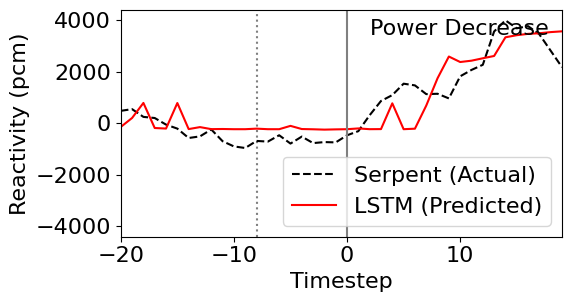

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

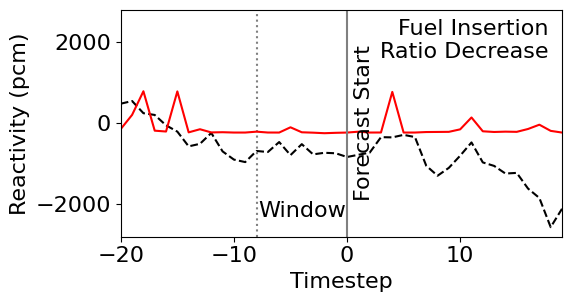

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

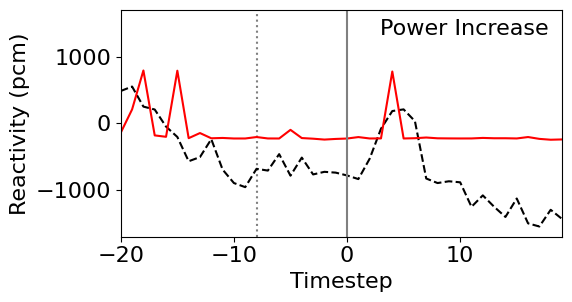

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

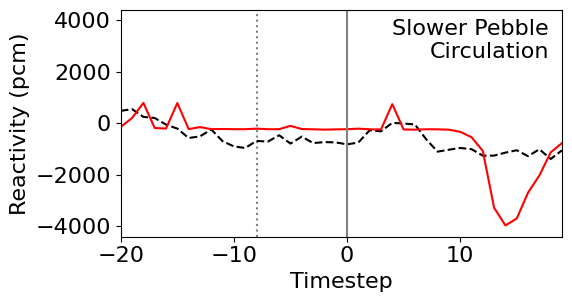

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

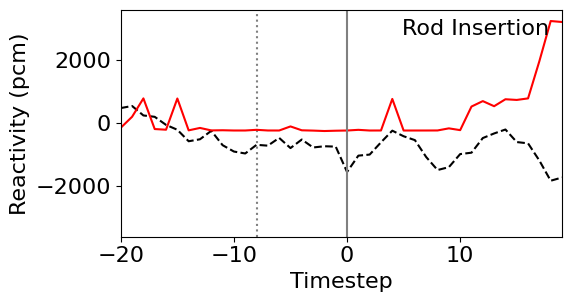

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 

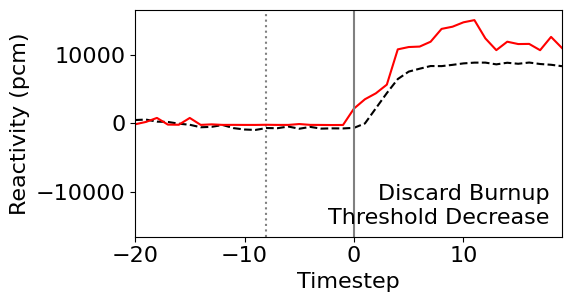

In [34]:
directory = "sequence_data"

forecast_sequences = {"gFHR_forecast_power_down":"Power Decrease",
                     "gFHR_forecast_graphite_up":"Fuel Insertion\nRatio Decrease",
                      "gFHR_forecast_power_up":"Power Increase",
                     "gFHR_forecast_circulation_slower":"Slower Pebble\nCirculation",
                     "gFHR_forecast_rods_in":"Rod Insertion",
                     "gFHR_forecast_threshold_down":"Discard Burnup\nThreshold Decrease"}
#fit_test_sequence = "gFHR_forecast_base"
#generalize_test_sequence = "gFHR_sequence7"
first_plot = True
second_plot = False

for sequence_name in forecast_sequences.keys():
    title = forecast_sequences[sequence_name]
    
    
    forecast_input_df = add_computed_features( pd.read_csv(f"{directory}/{sequence_name}_inputs.csv.gz", index_col=0)).drop(columns=["fima_discharge_rel_std"])
    forecast_input_time = forecast_input_df["cumulative_time"]
    forecast_input_df = forecast_input_df.drop(columns=["cumulative_time"])
    forecast_output_df = add_computed_targets( pd.read_csv(f"{directory}/{sequence_name}_outputs.csv.gz", index_col=0))

    history_keff_predicted = lstm.predict(forecast_input_df[-49:-20], predict_labels)["reactivity"]
    history_keff_actual = forecast_output_df[-40:-20]["reactivity"]
    
    #y_fit_test_predict = lstm.predict(forecast_input_df, predict_labels)
    forecast_slice = forecast_input_df[-27:-19].to_numpy().reshape(1, 8, len(forecast_input_df.columns))
    forecasted_keff_predicted = lstm.forecast(forecast_slice, 20, dependent_input_labels, predict_labels=["reactivity"])["reactivity"]*target_std["reactivity"]+target_mean["reactivity"]
    forecasted_keff_actual =  forecast_output_df[-20:]["reactivity"]

    fig, ax = plt.subplots(figsize=(6,3.3))
    timestep = np.arange(-20,20)
    plt.plot(timestep, 1E5*pd.concat([history_keff_actual, forecasted_keff_actual]), color="black", linestyle="dashed", label='Serpent (Actual)')
    plt.plot(timestep, 1E5*pd.concat([history_keff_predicted, forecasted_keff_predicted]), color="red", label="LSTM (Predicted)")
    ymin = np.min( pd.concat([history_keff_actual, forecasted_keff_actual, 
                              history_keff_predicted, forecasted_keff_predicted]))
                  
    ymax = np.max( pd.concat([history_keff_actual, forecasted_keff_actual, 
                              history_keff_predicted, forecasted_keff_predicted]))

    yabs = round(1.1*max( 1E5*np.abs([ymin, ymax]) ), -2)
    print(yabs)
    
    if second_plot:
        plt.text(1.5, 0, "Forecast Start", ha="center", va="center", zorder=2, rotation="vertical")
        plt.text(-4, -0.86*yabs, "Window", ha="center", va="bottom", zorder=-1)
        second_plot = False
    if first_plot:
        plt.legend(loc="lower right")
        first_plot = False
        second_plot = True

    if sequence_name == "gFHR_forecast_threshold_down":
        plt.text(0.97, 0.04, title, ha='right', verticalalignment='bottom', transform = ax.transAxes)
    else:
        plt.text(0.97, 0.96, title, ha='right', verticalalignment='top', transform = ax.transAxes)

    plt.xlabel("Timestep")
    plt.ylabel("Reactivity (pcm)")
    plt.vlines(0, -yabs, yabs, color="gray")
    plt.vlines(-8, -yabs, yabs, linestyle="dotted", zorder=-1, color="gray")
    plt.xlim(-20,19)
    plt.ylim(-yabs, yabs)

    plt.tight_layout()
    plt.savefig(f"figures/forecasting/{sequence_name}.png")
    plt.show()
    #fit_test_input, fit_test_output = prepare_sequence(fit_test_input_df, fit_test_output_df, window_length)
    #geneneralize_test_input, generalize_test_output = prepare_sequence(generalize_test_input_df, generalize_test_output_df, window_length)
    

In [ ]:
forecast_output_df[-20:]["final_analog_keff"]

In [ ]:
forecasted_keff_predicted*target_std[0]+target_mean[0]

In [ ]:
target_std["reactivity"]

In [ ]:
forecast_output_df["final_analog_keff"][-20:]

# Miscellaneous Plotting Codes

In [24]:
input_df

,power,burnup_step,graphite_insertion_fraction,control_rod_position,fima_discharge_threshold,R1_avg_FIMA_last_pass,R2_avg_FIMA_last_pass,R3_avg_FIMA_last_pass,R4_avg_FIMA_last_pass,burnup_bin1_count,burnup_bin2_count,burnup_bin3_count,burnup_bin4_count,burnup_bin5_count,burnup_bin6_count,burnup_bin7_count,burnup_bin8_count,burnup_bin9_count,avg_FIMA,num_discarded
0,70000000.0,6.525,0.875,369.47,18.63,2.581710,2.178163,1.816353,1.597046,2318.0,790.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.050174,0.0
1,140000000.0,6.525,0.750,369.47,18.63,3.026771,2.546907,2.106705,1.804342,1529.0,1579.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.379842,0.0
2,140000000.0,6.525,0.750,369.47,18.63,3.240983,2.731188,2.235860,1.915152,1529.0,1579.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.582444,0.0
3,140000000.0,6.525,0.750,369.47,18.63,3.587379,3.009689,2.470170,2.106673,745.0,2363.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.899467,0.0
4,140000000.0,6.525,0.750,369.47,18.63,4.025305,3.380150,2.780652,2.386271,0.0,3108.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.319587,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,210000000.0,6.525,0.000,369.47,18.63,1.776124,1.568064,1.412858,1.544864,1687.0,567.0,2363.0,411.0,3422.0,7015.0,7116.0,2295.0,0.0,12.820229,1848.0
117,210000000.0,6.525,0.000,369.47,18.63,1.778270,1.566669,1.405950,1.529110,2244.0,764.0,2180.0,2885.0,2140.0,5367.0,4270.0,5026.0,0.0,12.308703,4187.0
118,210000000.0,6.525,0.000,369.47,18.63,1.880571,1.660797,1.487273,1.620829,3479.0,1186.0,3294.0,2845.0,1979.0,5602.0,4201.0,2290.0,0.0,10.549382,1615.0
119,210000000.0,6.525,0.000,369.47,18.63,1.654410,1.453243,1.305913,1.430698,2393.0,0.0,762.0,1875.0,5835.0,5642.0,5411.0,2937.0,21.0,12.580336,2197.0


In [103]:
def make_good_spaghetti_plot_dual(input_plot_structure, second_input_structure):
    
    axis_num = -1
    number_plots = len(input_plot_structure.keys())
    fig, ax = plt.subplots(nrows=number_plots, ncols=1, figsize=(8,8.25),sharex=True,gridspec_kw = {'wspace':0, 'hspace':0})
    
    
    for primary_key in input_plot_structure.keys():
        axis_num += 1
        for secondary_key in input_plot_structure.keys():
            if primary_key == secondary_key:
                data = inpgut_plot_structure[secondary_key][0]
                parameter_type = input_plot_structure[secondary_key][1]
                color_to_use = parameter_color_scheme[parameter_type]
                ax[axis_num].plot(time, data, color=color_to_use,zorder=20, linewidth=2.5)
            else:
                data = input_plot_structure[secondary_key][0]
                ax[axis_num].plot(time, data, color="gray")
        for secondary_key in second_input_structure.keys():
            data = second_input_structure[secondary_key][0]
            ax[axis_num].plot(time, data, color="gray")
        if axis_num != (number_plots-1):
            ax[axis_num].set_xticks([])
        if parameter_type in ("input, dependent_input"):
            ax[axis_num].set_yticks([0,1])
            ax[axis_num].set_ylim(-0.25, 1.4)
        else:
            ax[axis_num].set_yticks([-1,1])
            ax[axis_num].set_ylim(-1.4, 1.4)
        ax[axis_num].set_ylabel(primary_key+" ", rotation=0, ha="right", va="center")
    
    fig.tight_layout()
    
    plt.show()


def make_good_spaghetti_plot(input_plot_structure, sequence_name, b_show=False):
    
    axis_num = -1
    number_plots = len(input_plot_structure.keys())
    plot_height = number_plots*1.15
    fig, ax = plt.subplots(nrows=number_plots, ncols=1, figsize=(8,plot_height),sharex=True,gridspec_kw = {'wspace':0, 'hspace':0})
    
    
    for primary_key in input_plot_structure.keys():
        axis_num += 1
        for secondary_key in input_plot_structure.keys():
            if primary_key == secondary_key:
                data = input_plot_structure[secondary_key][0]
                parameter_type = input_plot_structure[secondary_key][1]
                color_to_use = parameter_color_scheme[parameter_type]
                ax[axis_num].plot(time, data, color=color_to_use,zorder=20, linewidth=2.5)
            else:
                data = input_plot_structure[secondary_key][0]
                ax[axis_num].plot(time, data, color="gray", linewidth=0.3)
        if axis_num != (number_plots-1):
            ax[axis_num].set_xticks([])
        if parameter_type in ("input, dependent_input"):
            ax[axis_num].set_yticks([0,1])
            ax[axis_num].set_ylim(-0.25, 1.4)
        else:
            ax[axis_num].set_yticks([-1,1])
            ax[axis_num].set_ylim(-1.4, 1.4)
        ax[axis_num].set_ylabel(primary_key+" ", rotation=0, ha="right", va="center", fontsize=17)
    fig.tight_layout()
    plt.savefig(f"figures/{sequence_name}.png")
    if b_show:
        plt.show()



ERROR! Session/line number was not unique in database. History logging moved to new session 1382


In [7]:
def plot_all_sequence_data(input_df, output_df, show_main=True, show_all=False):
    
    input_df = add_computed_features(input_df)
    output_df = add_computed_targets(output_df)
    
    
    # Preparation of variables
    time = input_df["cumulative_time"] 
    power = input_df["power"]/280e6
    fuel_insertion_fraction = 1-input_df["graphite_insertion_fraction"]
    discard_threshold = input_df["fima_discharge_threshold"]/18.63
    circulation_rate = 6.525/input_df["burnup_step"]
    control_rod_insertion = (369.47-input_df["control_rod_position"])/309.47
    
    num_discarded = input_df["num_discarded"]/max(input_df["num_discarded"])
    
    avg_power_per_pebble = input_df["average_power_per_pebble"]/max(input_df["average_power_per_pebble"])
    
    
    output_df_std, _, _ = standardize(output_df, target_mean, target_std)
    
    keff = output_df["final_analog_keff"]
    reactivity = output_df["reactivity"]/max(np.abs(output_df["reactivity"]))
    discharge_burnup = input_df["avg_FIMA"]/max(input_df["avg_FIMA"])
    center_last_pass_fima = input_df["R1_avg_FIMA_last_pass"]/max(input_df["R1_avg_FIMA_last_pass"])
    last_pass_fima_R1 = center_last_pass_fima
    last_pass_fima_R2 = input_df["R2_avg_FIMA_last_pass"]/max(input_df["R2_avg_FIMA_last_pass"])
    last_pass_fima_R3 = input_df["R3_avg_FIMA_last_pass"]/max(input_df["R3_avg_FIMA_last_pass"])
    last_pass_fima_R4 = input_df["R4_avg_FIMA_last_pass"]/max(input_df["R4_avg_FIMA_last_pass"])
    
    flux_pca_vals = flux_pca.transform(output_df_std[flux_columns])
    power_pca_vals = power_pca.transform(output_df_std[power_columns])
    
    flux_pca_1 = flux_pca_vals[:,0] / max(np.abs(flux_pca_vals[:,0]))
    flux_pca_2 = flux_pca_vals[:,1] / max(np.abs(flux_pca_vals[:,1]))
    flux_pca_3 = flux_pca_vals[:,2] / max(np.abs(flux_pca_vals[:,2]))
    flux_pca_4 = flux_pca_vals[:,3] / max(np.abs(flux_pca_vals[:,3]))
    flux_pca_5 = flux_pca_vals[:,4] / max(np.abs(flux_pca_vals[:,4]))
    
    power_pca_1 = power_pca_vals[:,0] / max(np.abs(power_pca_vals[:,0]))
    power_pca_2 = power_pca_vals[:,1] / max(np.abs(power_pca_vals[:,1]))
    power_pca_3 = power_pca_vals[:,2] / max(np.abs(power_pca_vals[:,2]))
    power_pca_4 = power_pca_vals[:,3] / max(np.abs(power_pca_vals[:,3]))
    power_pca_5 = power_pca_vals[:,4] / max(np.abs(power_pca_vals[:,4]))

    burnup_bin_1 = input_df["burnup_bin1_count"] / max(np.abs(input_df["burnup_bin1_count"]))
    burnup_bin_2 = input_df["burnup_bin2_count"] / max(np.abs(input_df["burnup_bin2_count"]))
    burnup_bin_3 = input_df["burnup_bin3_count"] / max(np.abs(input_df["burnup_bin3_count"]))
    burnup_bin_4 = input_df["burnup_bin4_count"] / max(np.abs(input_df["burnup_bin4_count"]))
    burnup_bin_5 = input_df["burnup_bin5_count"] / max(np.abs(input_df["burnup_bin5_count"]))
    burnup_bin_6 = input_df["burnup_bin6_count"] / max(np.abs(input_df["burnup_bin6_count"]))
    burnup_bin_7 = input_df["burnup_bin7_count"] / max(np.abs(input_df["burnup_bin7_count"]))
    burnup_bin_8 = input_df["burnup_bin8_count"] / max(np.abs(input_df["burnup_bin8_count"]))
    burnup_bin_9 = input_df["burnup_bin9_count"] / max(np.abs(input_df["burnup_bin9_count"]))
    
    thermal_flux_middle = output_df["fluxR1Z5E1"]/max(output_df["fluxR1Z5E1"])
    power_middle = output_df["powerR1Z5"]/max(output_df["powerR1Z5"])
    fast_flux_lower_corner = output_df["fluxR4Z1E3"]/max(output_df["fluxR4Z1E3"])
    
    compare_parameter = "final_analog_keff"
    
    
    
    
    plt.rcParams.update({
        "figure.facecolor":  (1.0, 1.0, 1.0, 0.0),  # red   with alpha = 30%
        "axes.facecolor":    (1.0, 1.0, 1.0, 1),  # green with alpha = 50%
        "figure.autolayout": False
    })
    
    
    parameter_color_scheme = {
        "input": "blue",
        "dependent_input": "green",
        "output": "red"
    }
    
    
    key_input_variables_structure = {
        "Power": (power, "input"),
        "Fuel Insertion Fraction": (fuel_insertion_fraction, "input"),
        "Fuel Circulation Rate": (circulation_rate, "input"),
        "Burnup Discard Threshold": (discard_threshold, "input"),
        "Control Rod Insertion": (control_rod_insertion, "input"),
        "# Discarded Pebbles": (num_discarded, "dependent_input"),
    }

    key_output_variables_structure = {
        "Avg. Power Per Pebble": (avg_power_per_pebble, "dependent_input"),
        "Avg. Discharge Burnup": (discharge_burnup, "dependent_input"),
        "R1 Last Pass FIMA": (center_last_pass_fima, "dependent_input"),
        "Reactivity": (reactivity, "output"),
        "Flux PC 1": (flux_pca_1, "output"),
        "Power PC 1": (power_pca_1, "output"),
    }
    
    full_variables_1_structure = {
        "Power": (power, "input"),
        "Fuel Insertion Fraction": (fuel_insertion_fraction, "input"),
        "Fuel Circulation Rate": (circulation_rate, "input"),
        "Burnup Discard Threshold": (discard_threshold, "input"),
        "Control Rod Insertion": (control_rod_insertion, "input"),
        "Avg. Discharge Burnup": (discharge_burnup, "dependent_input"),
        "Reactivity": (reactivity, "output"),
    }

    full_variables_2_structure = {
        "Avg. Power Per Pebble": (avg_power_per_pebble, "dependent_input"),
        "R1 Last Pass FIMA": (last_pass_fima_R1, "dependent_input"),
        "R2 Last Pass FIMA": (last_pass_fima_R2, "dependent_input"),
        "R3 Last Pass FIMA": (last_pass_fima_R3, "dependent_input"),
        "R4 Last Pass FIMA": (last_pass_fima_R4, "dependent_input"),
    }

    full_variables_3_structure = {
        "Burnup Bin 1": (burnup_bin_1, "dependent_input"),
        "Burnup Bin 2": (burnup_bin_2, "dependent_input"),
        "Burnup Bin 3": (burnup_bin_3, "dependent_input"),
        "Burnup Bin 4": (burnup_bin_4, "dependent_input"),
        "Burnup Bin 5": (burnup_bin_5, "dependent_input"),
        "Burnup Bin 6": (burnup_bin_6, "dependent_input"),
        "Burnup Bin 7": (burnup_bin_7, "dependent_input"),
        "Burnup Bin 8": (burnup_bin_8, "dependent_input"),
        "Burnup Bin 9": (burnup_bin_9, "dependent_input"),
        "# Discarded Pebbles": (num_discarded, "dependent_input"),
    }

    full_variables_4_structure = {
        "Power Middle R1Z5": (power_middle, "output"),
        "Power PC 1": (power_pca_1, "output"),
        "Power PC 2": (power_pca_2, "output"),
        "Power PC 3": (power_pca_3, "output"),
        "Power PC 4": (power_pca_4, "output"),
        "Power PC 5": (power_pca_5, "output"),
        
    }

    full_variables_5_structure = {
        "Thermal Flux R1Z5": (thermal_flux_middle, "output"),
        "Flux PC 1": (flux_pca_1, "output"),
        "Flux PC 2": (flux_pca_2, "output"),
        "Flux PC 3": (flux_pca_3, "output"),
        "Flux PC 4": (flux_pca_4, "output"),
        "Flux PC 5": (flux_pca_5, "output"),        
    }


    make_good_spaghetti_plot(key_input_variables_structure, "sequence_plots/"+file_name+"_inputs", b_show=show_main)
    make_good_spaghetti_plot(key_output_variables_structure, "sequence_plots/"+file_name+"_outputs", b_show=show_main)
    make_good_spaghetti_plot(full_variables_1_structure, "sequence_full_plots/"+file_name+"_full_1", b_show=show_all)
    make_good_spaghetti_plot(full_variables_2_structure, "sequence_full_plots/"+file_name+"_full_2", b_show=show_all)
    make_good_spaghetti_plot(full_variables_3_structure, "sequence_full_plots/"+file_name+"_full_3", b_show=show_all)
    make_good_spaghetti_plot(full_variables_4_structure, "sequence_full_plots/"+file_name+"_full_4", b_show=show_all)
    make_good_spaghetti_plot(full_variables_5_structure, "sequence_full_plots/"+file_name+"_full_5", b_show=show_all)

gFHR_sequence
gFHR_sequence2
gFHR_sequence3


/tmp/ipykernel_1758342/4139160358.py:42: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=number_plots, ncols=1, figsize=(8,plot_height),sharex=True,gridspec_kw = {'wspace':0, 'hspace':0})


gFHR_sequence4
gFHR_sequence5
gFHR_sequence6
gFHR_sequence7
gFHR_sequence8
gFHR_sequence9
gFHR_sequence10
gFHR_sequence11
gFHR_sequence12
gFHR_sequence13
gFHR_sequence14
gFHR_automated1
gFHR_automated2
gFHR_automated3
gFHR_automated4
gFHR_automated5
gFHR_automated6
gFHR_automated7
gFHR_automated8
gFHR_automated9
gFHR_automated10
gFHR_automated11
gFHR_forecast_base
gFHR_random_1
gFHR_random_2
gFHR_random_3
gFHR_random_4
gFHR_random_5
gFHR_random_6
gFHR_random_7


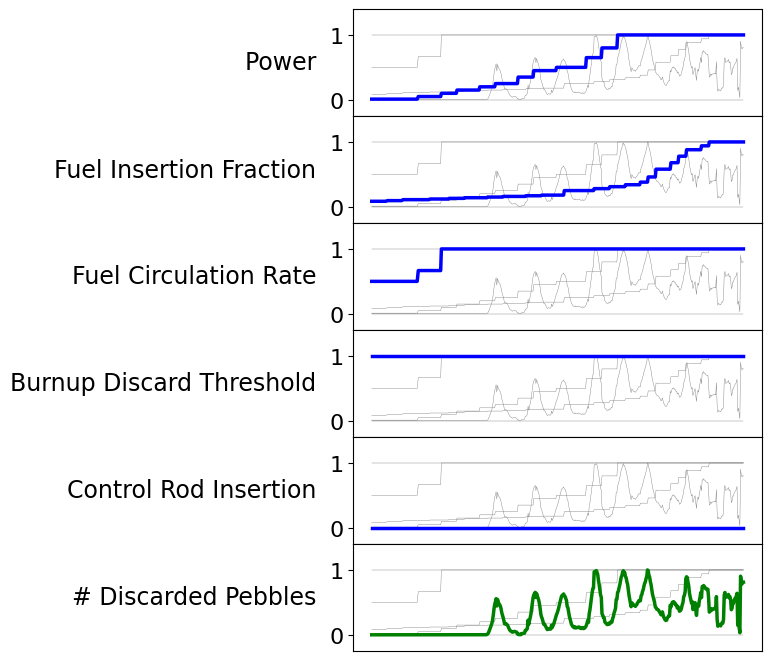

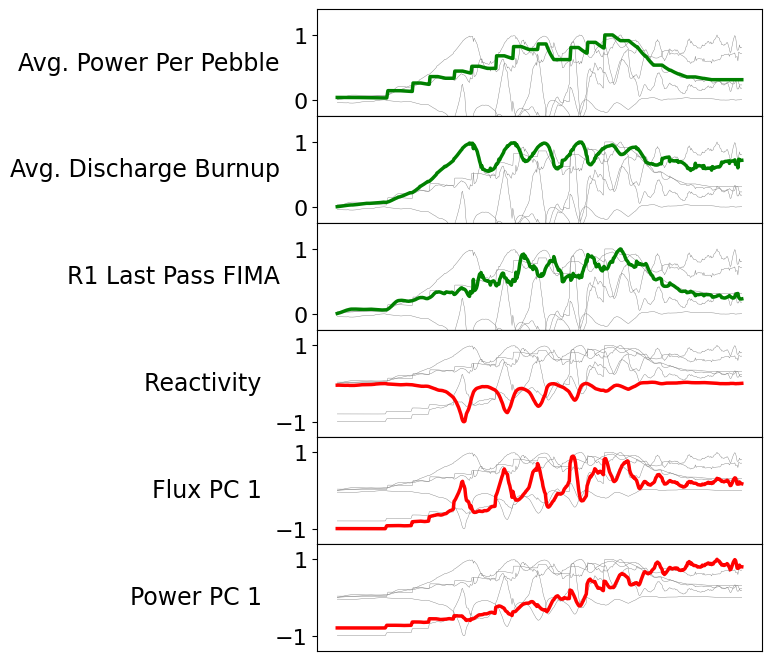

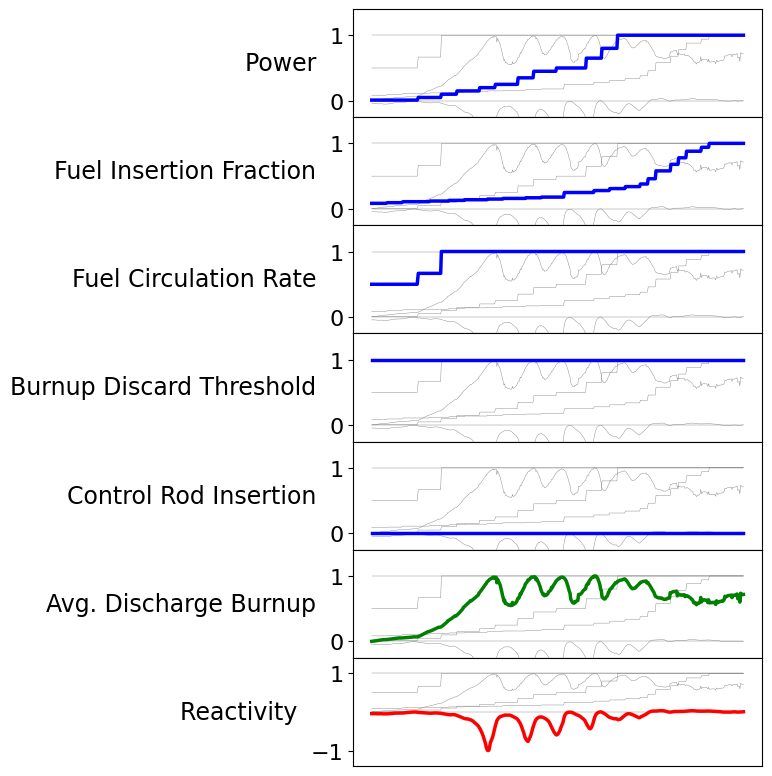

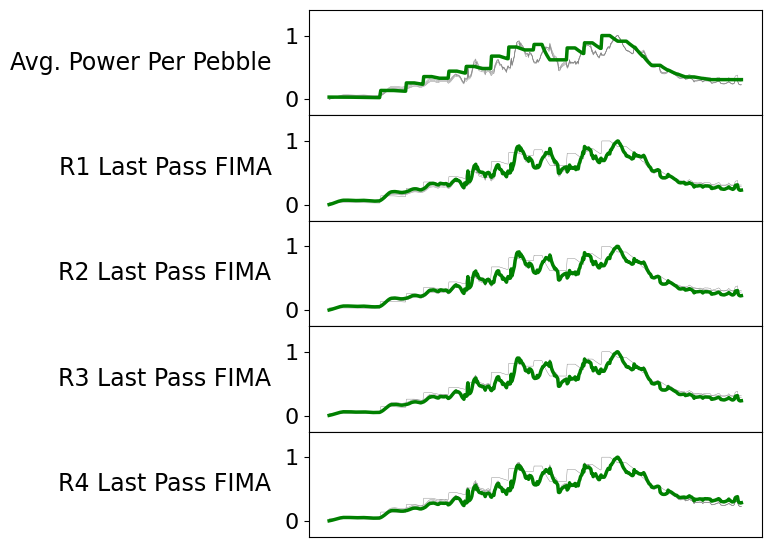

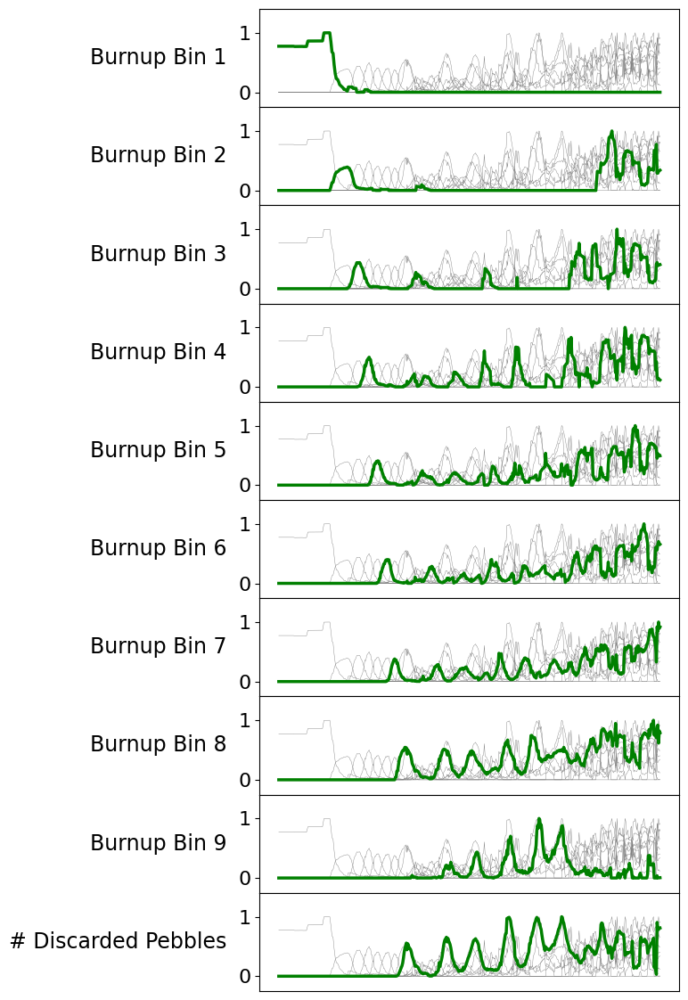

...

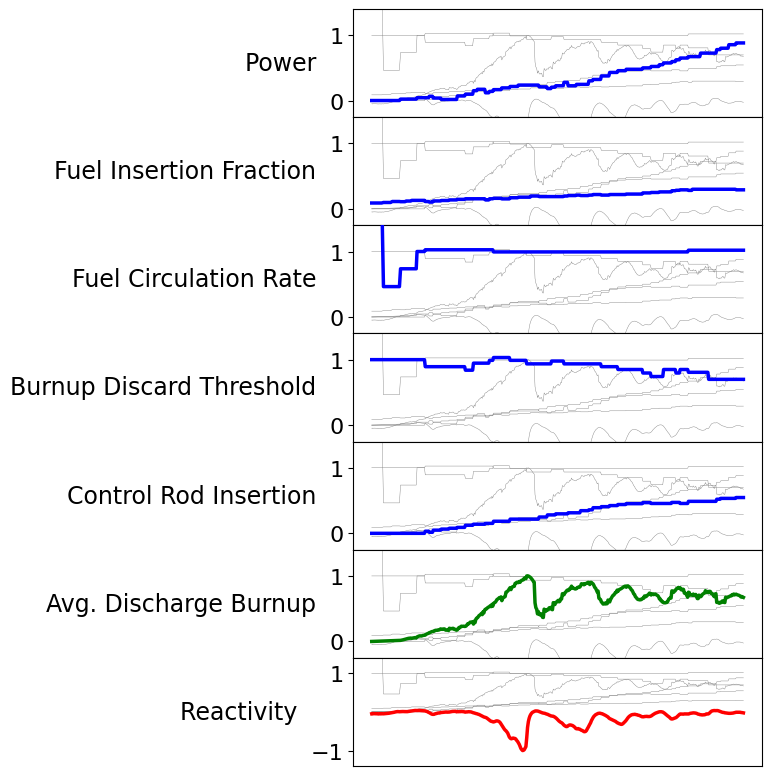

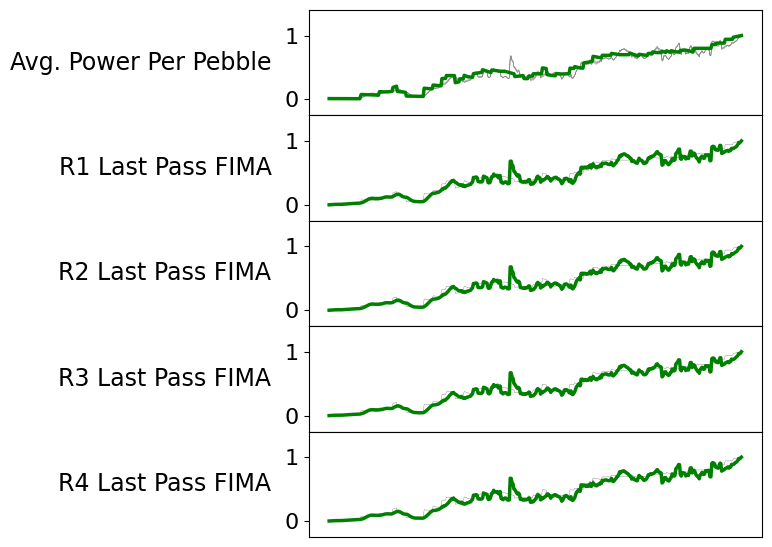

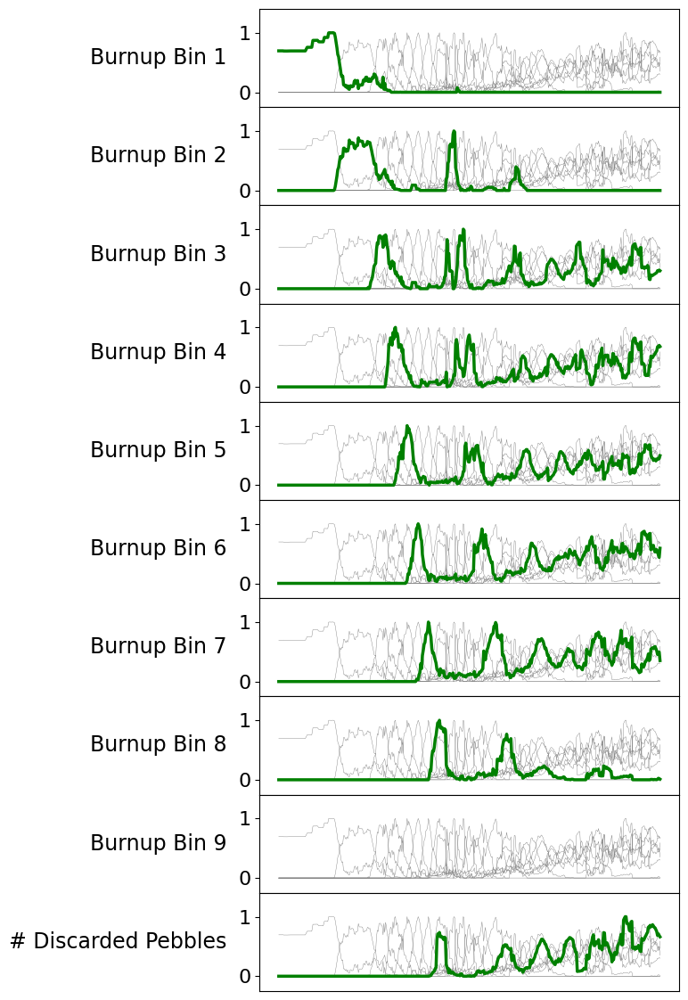

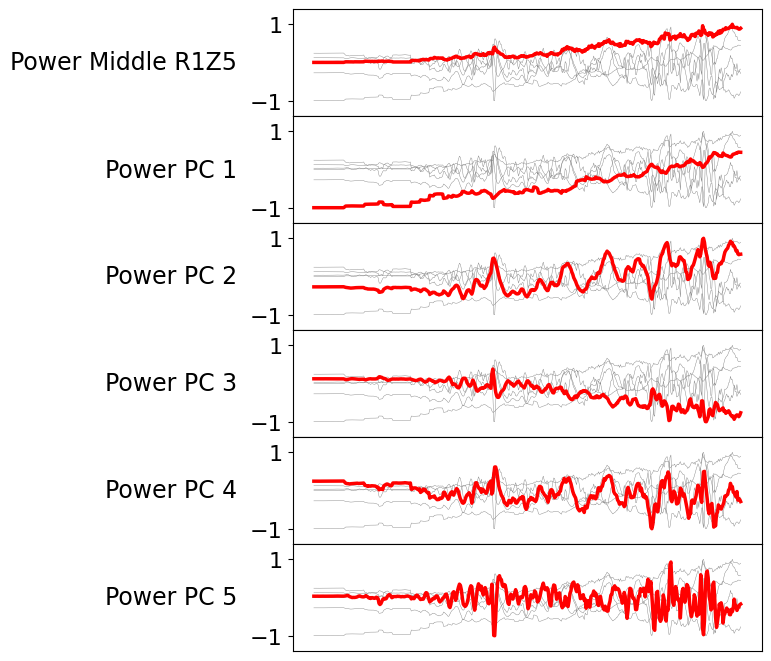

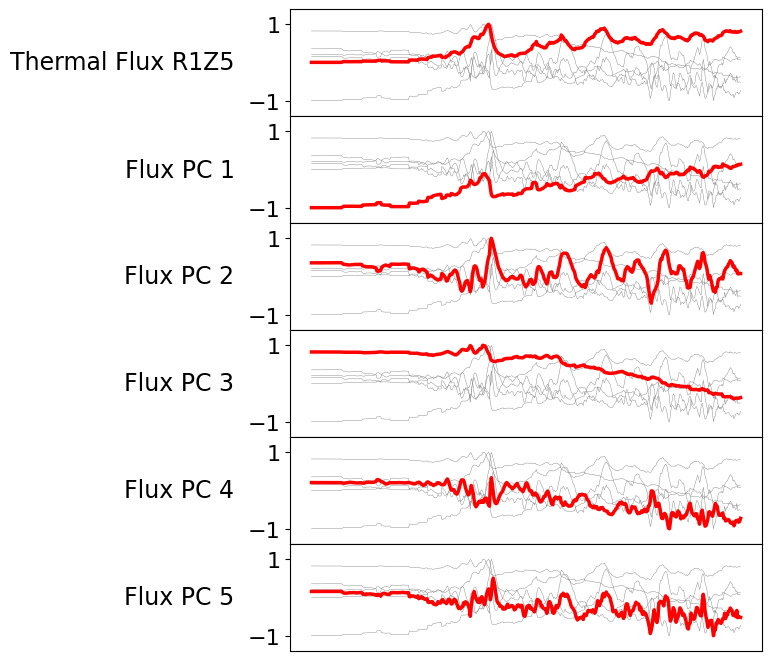

gFHR_random_8
gFHR_random_9
gFHR_random_10


/tmp/ipykernel_1758342/4139160358.py:42: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=number_plots, ncols=1, figsize=(8,plot_height),sharex=True,gridspec_kw = {'wspace':0, 'hspace':0})


gFHR_random_11
gFHR_random_12
gFHR_random_13
gFHR_random_14
gFHR_random_15
gFHR_random_16
gFHR_random_18
gFHR_random_19
gFHR_random_20


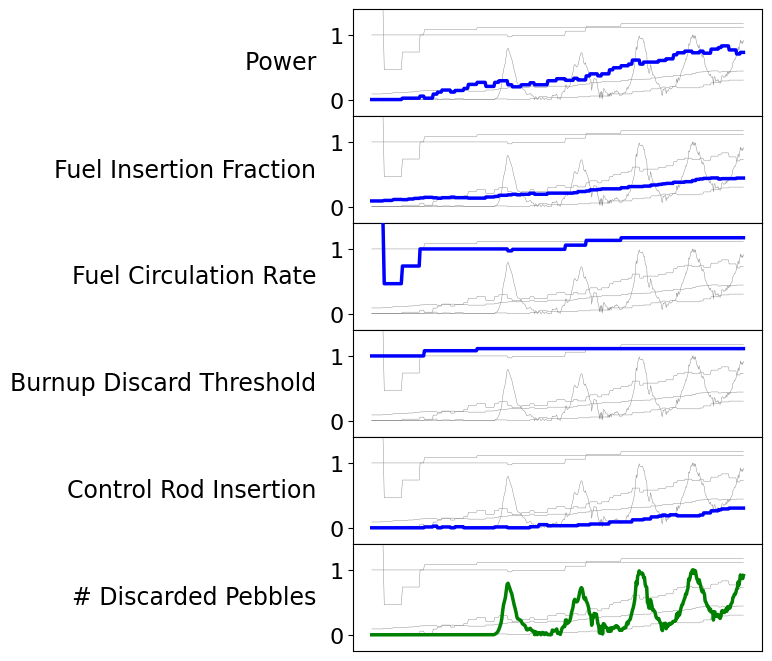

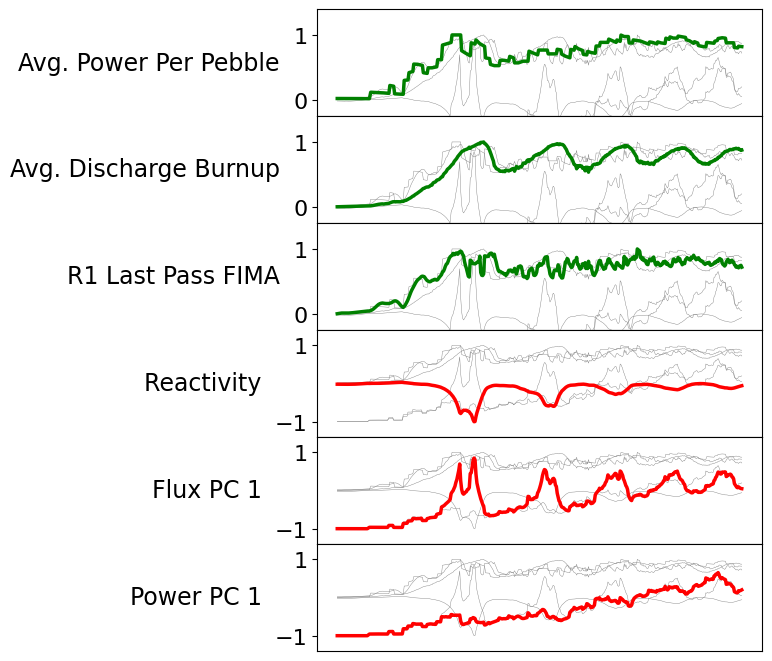

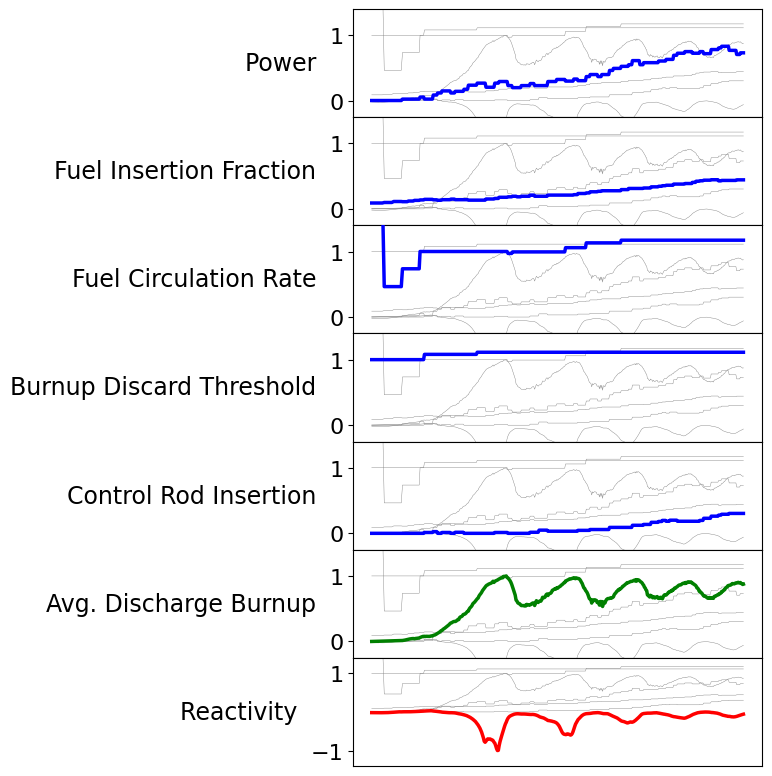

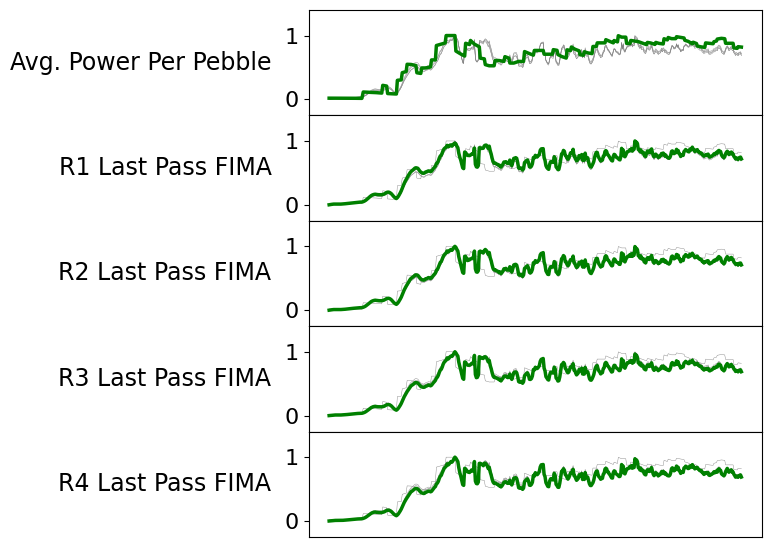

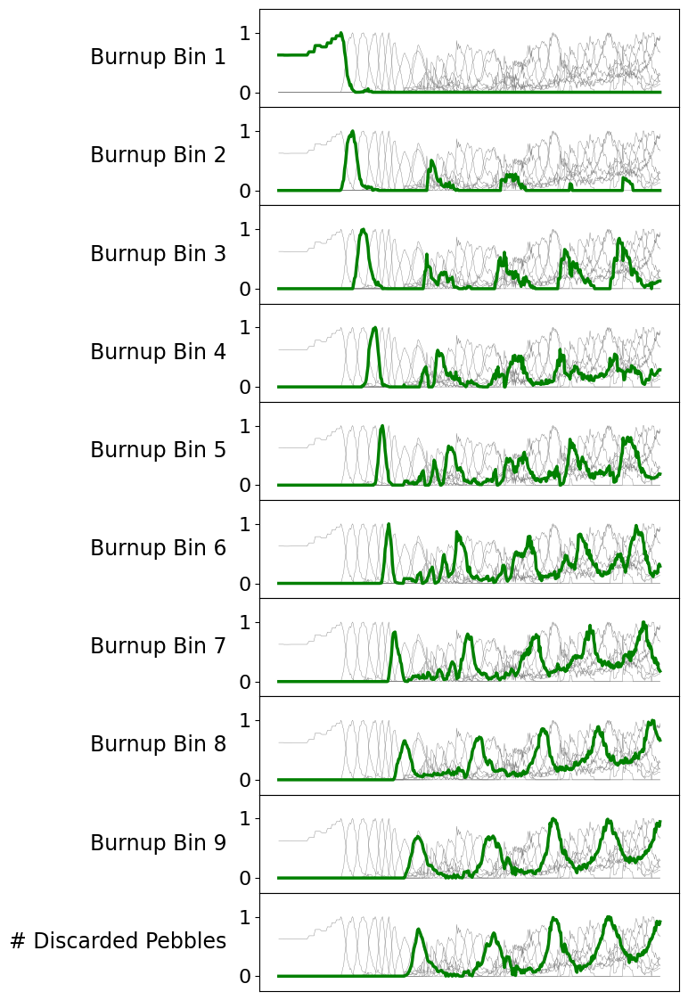

...

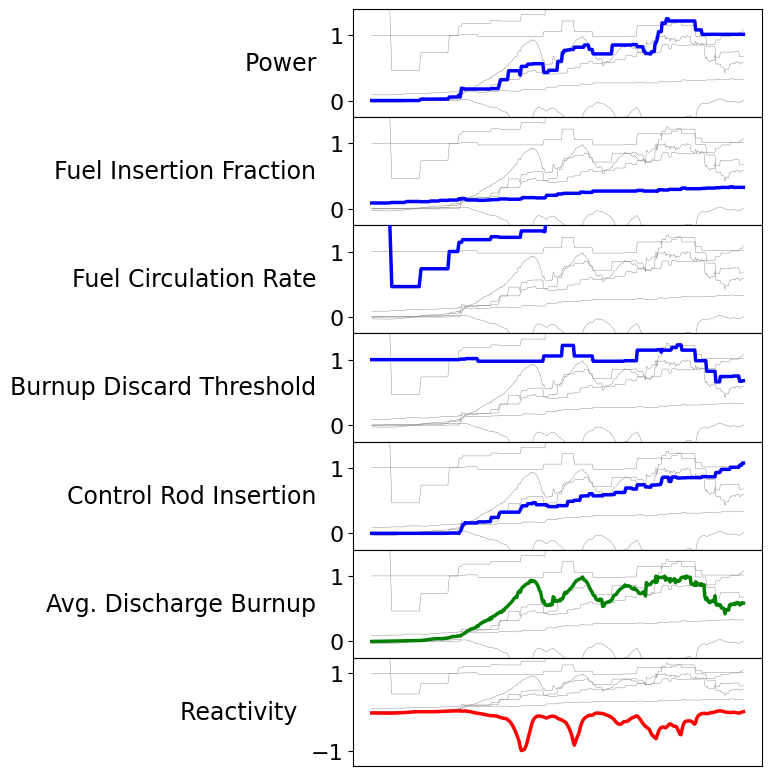

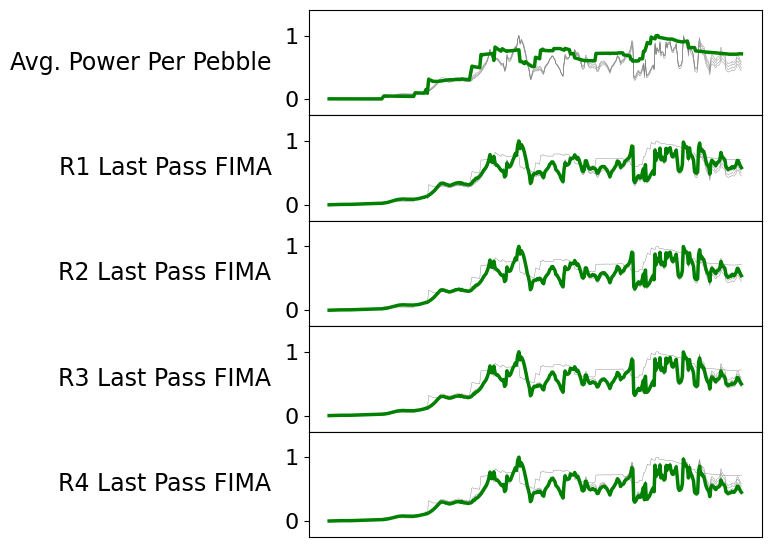

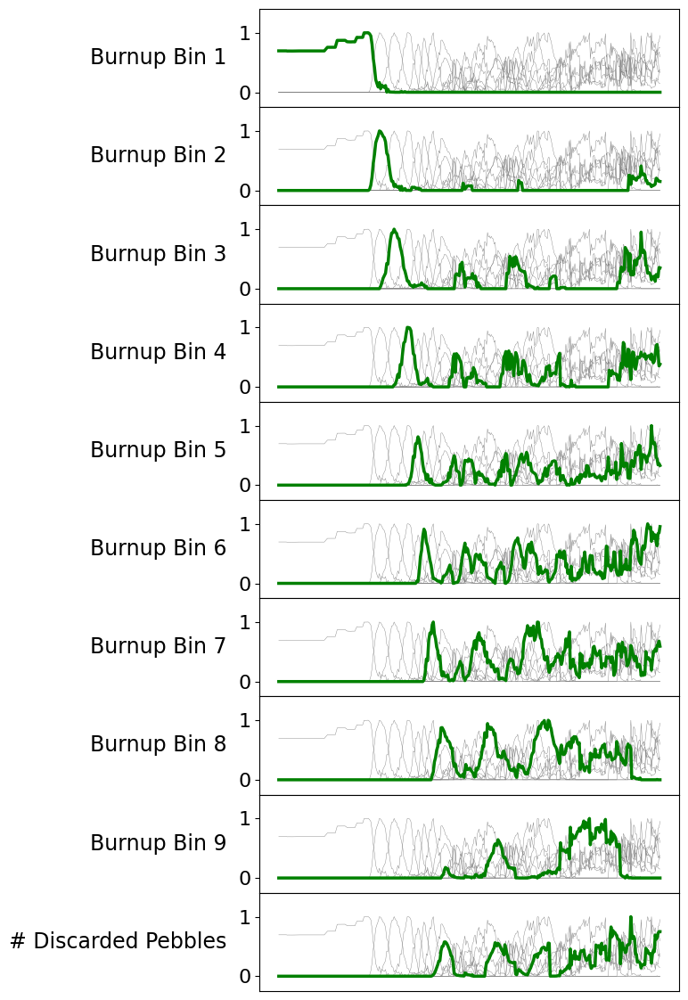

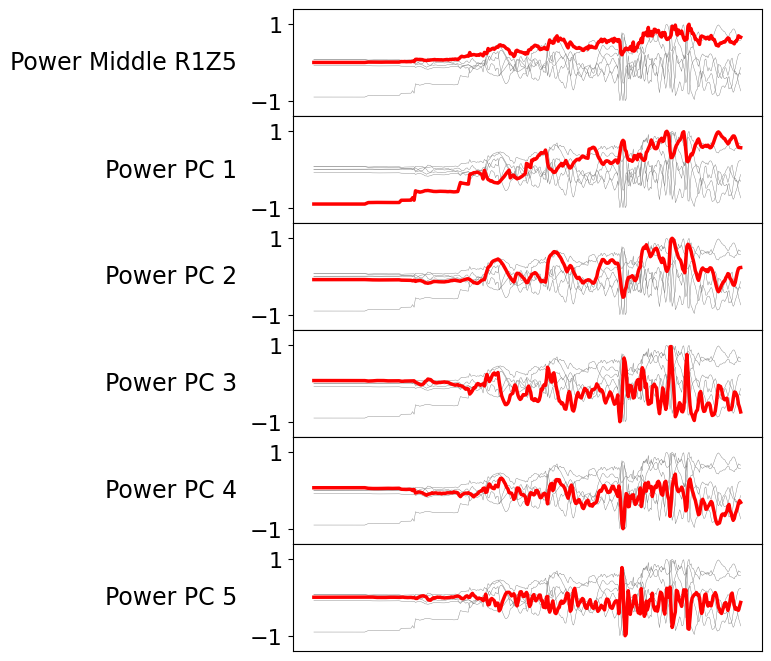

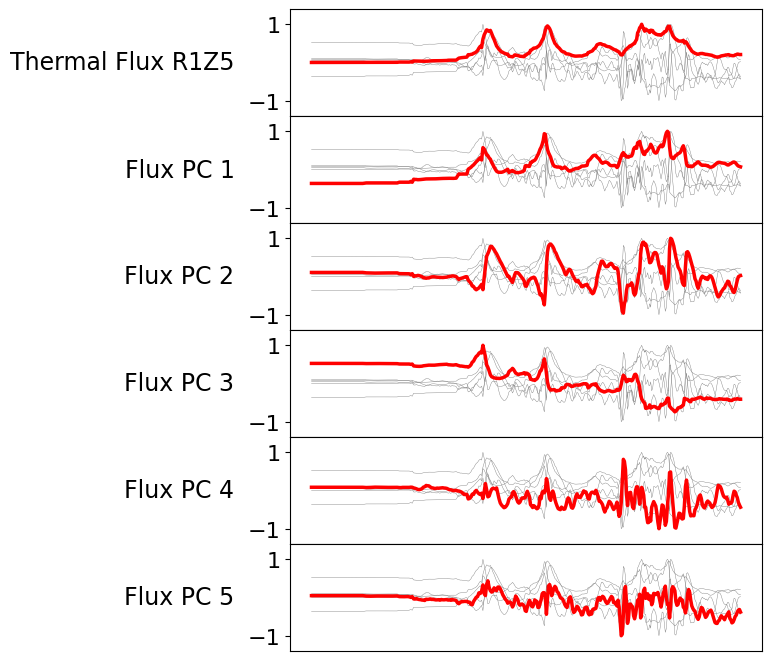

In [104]:
directory = "sequence_data"
show_name = "gFHR_random_7"
name = "Random Sequence"

for file_name in sequence_file_base_list:

    input_df = add_computed_features(pd.read_csv(f"{directory}/{file_name}_inputs.csv.gz", index_col=0))
    output_df = add_computed_targets(pd.read_csv(f"{directory}/{file_name}_outputs.csv.gz", index_col=0))
    
    
    # Preparation of variables
    time = input_df["cumulative_time"] 
    power = input_df["power"]/280e6
    fuel_insertion_fraction = 1-input_df["graphite_insertion_fraction"]
    discard_threshold = input_df["fima_discharge_threshold"]/18.63
    circulation_rate = 6.525/input_df["burnup_step"]
    control_rod_insertion = (369.47-input_df["control_rod_position"])/309.47
    
    num_discarded = input_df["num_discarded"]/max(input_df["num_discarded"])
    
    avg_power_per_pebble = input_df["average_power_per_pebble"]/max(input_df["average_power_per_pebble"])
    
    
    output_df_std, _, _ = standardize(output_df, target_mean, target_std)
    
    keff = output_df["final_analog_keff"]
    reactivity = output_df["reactivity"]/max(np.abs(output_df["reactivity"]))
    discharge_burnup = input_df["avg_FIMA"]/max(input_df["avg_FIMA"])
    center_last_pass_fima = input_df["R1_avg_FIMA_last_pass"]/max(input_df["R1_avg_FIMA_last_pass"])
    last_pass_fima_R1 = center_last_pass_fima
    last_pass_fima_R2 = input_df["R2_avg_FIMA_last_pass"]/max(input_df["R2_avg_FIMA_last_pass"])
    last_pass_fima_R3 = input_df["R3_avg_FIMA_last_pass"]/max(input_df["R3_avg_FIMA_last_pass"])
    last_pass_fima_R4 = input_df["R4_avg_FIMA_last_pass"]/max(input_df["R4_avg_FIMA_last_pass"])
    
    flux_pca_vals = flux_pca.transform(output_df_std[flux_columns])
    power_pca_vals = power_pca.transform(output_df_std[power_columns])
    
    flux_pca_1 = flux_pca_vals[:,0] / max(np.abs(flux_pca_vals[:,0]))
    flux_pca_2 = flux_pca_vals[:,1] / max(np.abs(flux_pca_vals[:,1]))
    flux_pca_3 = flux_pca_vals[:,2] / max(np.abs(flux_pca_vals[:,2]))
    flux_pca_4 = flux_pca_vals[:,3] / max(np.abs(flux_pca_vals[:,3]))
    flux_pca_5 = flux_pca_vals[:,4] / max(np.abs(flux_pca_vals[:,4]))
    
    power_pca_1 = power_pca_vals[:,0] / max(np.abs(power_pca_vals[:,0]))
    power_pca_2 = power_pca_vals[:,1] / max(np.abs(power_pca_vals[:,1]))
    power_pca_3 = power_pca_vals[:,2] / max(np.abs(power_pca_vals[:,2]))
    power_pca_4 = power_pca_vals[:,3] / max(np.abs(power_pca_vals[:,3]))
    power_pca_5 = power_pca_vals[:,4] / max(np.abs(power_pca_vals[:,4]))

    burnup_bin_1 = input_df["burnup_bin1_count"] / max(np.abs(input_df["burnup_bin1_count"]))
    burnup_bin_2 = input_df["burnup_bin2_count"] / max(np.abs(input_df["burnup_bin2_count"]))
    burnup_bin_3 = input_df["burnup_bin3_count"] / max(np.abs(input_df["burnup_bin3_count"]))
    burnup_bin_4 = input_df["burnup_bin4_count"] / max(np.abs(input_df["burnup_bin4_count"]))
    burnup_bin_5 = input_df["burnup_bin5_count"] / max(np.abs(input_df["burnup_bin5_count"]))
    burnup_bin_6 = input_df["burnup_bin6_count"] / max(np.abs(input_df["burnup_bin6_count"]))
    burnup_bin_7 = input_df["burnup_bin7_count"] / max(np.abs(input_df["burnup_bin7_count"]))
    burnup_bin_8 = input_df["burnup_bin8_count"] / max(np.abs(input_df["burnup_bin8_count"]))
    burnup_bin_9 = input_df["burnup_bin9_count"] / max(np.abs(input_df["burnup_bin9_count"]))
    
    thermal_flux_middle = output_df["fluxR1Z5E1"]/max(output_df["fluxR1Z5E1"])
    power_middle = output_df["powerR1Z5"]/max(output_df["powerR1Z5"])
    fast_flux_lower_corner = output_df["fluxR4Z1E3"]/max(output_df["fluxR4Z1E3"])
    
    compare_parameter = "final_analog_keff"
    
    
    
    
    plt.rcParams.update({
        "figure.facecolor":  (1.0, 1.0, 1.0, 0.0),  # red   with alpha = 30%
        "axes.facecolor":    (1.0, 1.0, 1.0, 1),  # green with alpha = 50%
        "figure.autolayout": False
    })
    
    
    parameter_color_scheme = {
        "input": "blue",
        "dependent_input": "green",
        "output": "red"
    }
    
    
    key_input_variables_structure = {
        "Power": (power, "input"),
        "Fuel Insertion Fraction": (fuel_insertion_fraction, "input"),
        "Fuel Circulation Rate": (circulation_rate, "input"),
        "Burnup Discard Threshold": (discard_threshold, "input"),
        "Control Rod Insertion": (control_rod_insertion, "input"),
        "# Discarded Pebbles": (num_discarded, "dependent_input"),
    }

    key_output_variables_structure = {
        "Avg. Power Per Pebble": (avg_power_per_pebble, "dependent_input"),
        "Avg. Discharge Burnup": (discharge_burnup, "dependent_input"),
        "R1 Last Pass FIMA": (center_last_pass_fima, "dependent_input"),
        "Reactivity": (reactivity, "output"),
        "Flux PC 1": (flux_pca_1, "output"),
        "Power PC 1": (power_pca_1, "output"),
    }
    
    full_variables_1_structure = {
        "Power": (power, "input"),
        "Fuel Insertion Fraction": (fuel_insertion_fraction, "input"),
        "Fuel Circulation Rate": (circulation_rate, "input"),
        "Burnup Discard Threshold": (discard_threshold, "input"),
        "Control Rod Insertion": (control_rod_insertion, "input"),
        "Avg. Discharge Burnup": (discharge_burnup, "dependent_input"),
        "Reactivity": (reactivity, "output"),
    }

    full_variables_2_structure = {
        "Avg. Power Per Pebble": (avg_power_per_pebble, "dependent_input"),
        "R1 Last Pass FIMA": (last_pass_fima_R1, "dependent_input"),
        "R2 Last Pass FIMA": (last_pass_fima_R2, "dependent_input"),
        "R3 Last Pass FIMA": (last_pass_fima_R3, "dependent_input"),
        "R4 Last Pass FIMA": (last_pass_fima_R4, "dependent_input"),
    }

    full_variables_3_structure = {
        "Burnup Bin 1": (burnup_bin_1, "dependent_input"),
        "Burnup Bin 2": (burnup_bin_2, "dependent_input"),
        "Burnup Bin 3": (burnup_bin_3, "dependent_input"),
        "Burnup Bin 4": (burnup_bin_4, "dependent_input"),
        "Burnup Bin 5": (burnup_bin_5, "dependent_input"),
        "Burnup Bin 6": (burnup_bin_6, "dependent_input"),
        "Burnup Bin 7": (burnup_bin_7, "dependent_input"),
        "Burnup Bin 8": (burnup_bin_8, "dependent_input"),
        "Burnup Bin 9": (burnup_bin_9, "dependent_input"),
        "# Discarded Pebbles": (num_discarded, "dependent_input"),
    }

    full_variables_4_structure = {
        "Power Middle R1Z5": (power_middle, "output"),
        "Power PC 1": (power_pca_1, "output"),
        "Power PC 2": (power_pca_2, "output"),
        "Power PC 3": (power_pca_3, "output"),
        "Power PC 4": (power_pca_4, "output"),
        "Power PC 5": (power_pca_5, "output"),
        
    }

    full_variables_5_structure = {
        "Thermal Flux R1Z5": (thermal_flux_middle, "output"),
        "Flux PC 1": (flux_pca_1, "output"),
        "Flux PC 2": (flux_pca_2, "output"),
        "Flux PC 3": (flux_pca_3, "output"),
        "Flux PC 4": (flux_pca_4, "output"),
        "Flux PC 5": (flux_pca_5, "output"),        
    }

    

    

    print(file_name)
    if show_name == file_name:
        b_show = True
    else:
        b_show = False
    make_good_spaghetti_plot(key_input_variables_structure, "sequence_plots/"+file_name+"_inputs", b_show=b_show)
    make_good_spaghetti_plot(key_output_variables_structure, "sequence_plots/"+file_name+"_outputs", b_show=b_show)
    make_good_spaghetti_plot(full_variables_1_structure, "sequence_full_plots/"+file_name+"_full_1", b_show=b_show)
    make_good_spaghetti_plot(full_variables_2_structure, "sequence_full_plots/"+file_name+"_full_2", b_show=b_show)
    make_good_spaghetti_plot(full_variables_3_structure, "sequence_full_plots/"+file_name+"_full_3", b_show=b_show)
    make_good_spaghetti_plot(full_variables_4_structure, "sequence_full_plots/"+file_name+"_full_4", b_show=b_show)
    make_good_spaghetti_plot(full_variables_5_structure, "sequence_full_plots/"+file_name+"_full_5", b_show=b_show)
    


In [44]:

def make_good_spaghetti_plot_automation(input_plot_structure, sequence_name, b_show=False, 
                             b_do_time=True, unnormalize_reactivity=False, show_control_labels=True):
    
    axis_num = -1
    number_plots = len(input_plot_structure.keys())
    if show_control_labels:
        fig, ax = plt.subplots(nrows=number_plots, ncols=1, figsize=(8,8.25),sharex=True,gridspec_kw = {'wspace':0, 'hspace':0})
    else:
        fig, ax = plt.subplots(nrows=number_plots, ncols=1, figsize=(5.5,8.25),sharex=True,gridspec_kw = {'wspace':0, 'hspace':0})
    
    
    for primary_key in input_plot_structure.keys():
        axis_num += 1
        for secondary_key in input_plot_structure.keys():
            if primary_key == secondary_key:
                data = input_plot_structure[secondary_key][0]
                parameter_type = input_plot_structure[secondary_key][1]
                color_to_use = parameter_color_scheme[parameter_type]
                ax[axis_num].plot(time, data, color=color_to_use,zorder=20, linewidth=2.5)
            elif secondary_key != "Reactivity (pcm)":
                data = input_plot_structure[secondary_key][0]
                ax[axis_num].plot(time, data, color="gray")
        if axis_num != (number_plots-1):
            ax[axis_num].set_xticks([])
        if primary_key != "Reactivity (pcm)":
            ax[axis_num].set_yticks([0,1])
            ax[axis_num].set_ylim(-0.15, 1.4)
        if show_control_labels:
            ax[axis_num].set_ylabel(primary_key+" ", rotation=0, ha="right", va="center")
    if unnormalize_reactivity:
        max_reactivity = round(np.max(np.abs( input_plot_structure["Reactivity (pcm)"][0]) ),-2)
        ax[axis_num].set_yticks([-max_reactivity,-max_reactivity*0.5,0,max_reactivity*0.5,max_reactivity])
        ax[axis_num].set_ylim(-max_reactivity*1.15, max_reactivity*1.15)
    if b_do_time:
        ax[axis_num].set_xticks(np.linspace(0,round(max(time),-2), 7))
        ax[axis_num].set_xlim([0,round(max(time),-2)])
    fig.tight_layout()
    plt.savefig(f"figures/{sequence_name}.png")
    if b_show:
        plt.show()

gFHR_automated10
gFHR_automated11


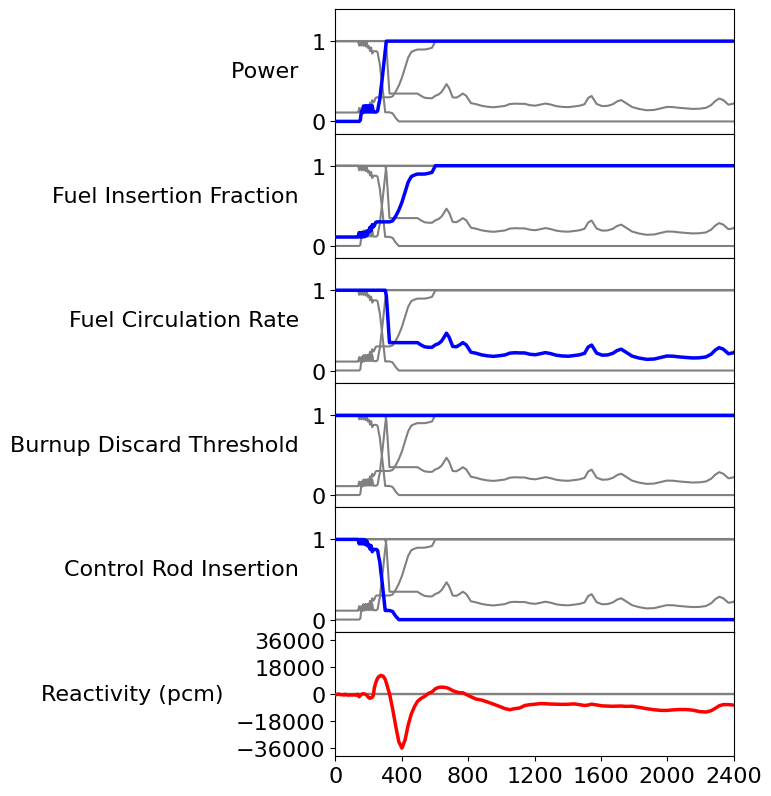

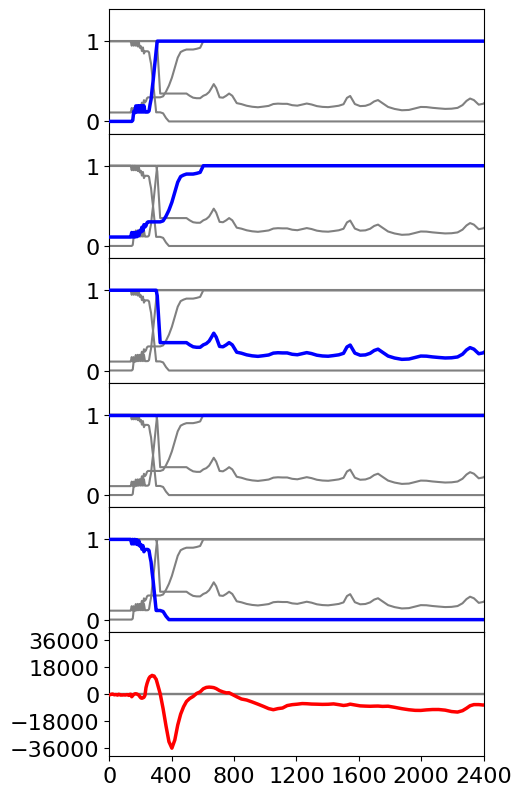

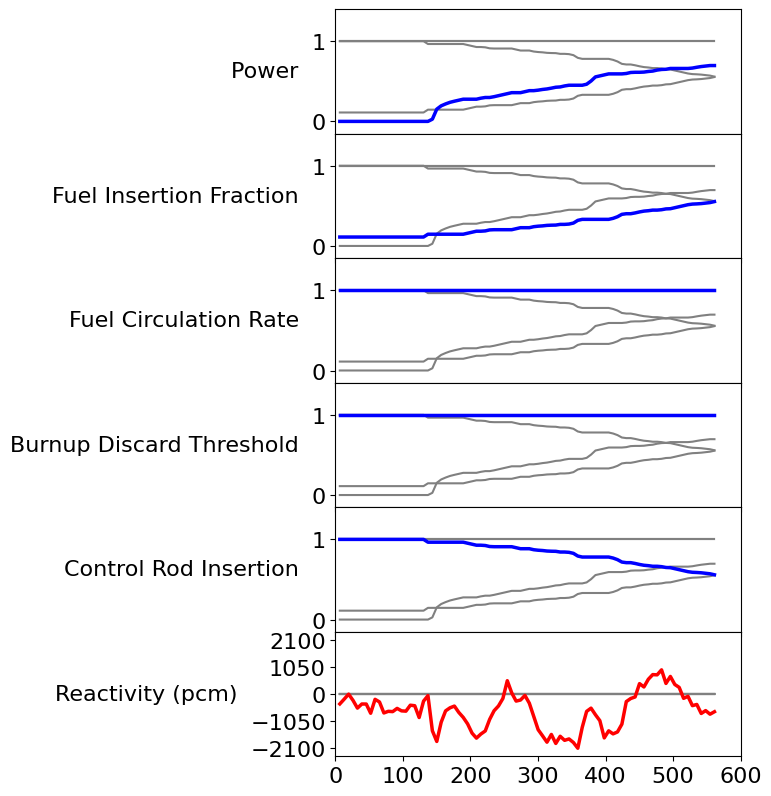

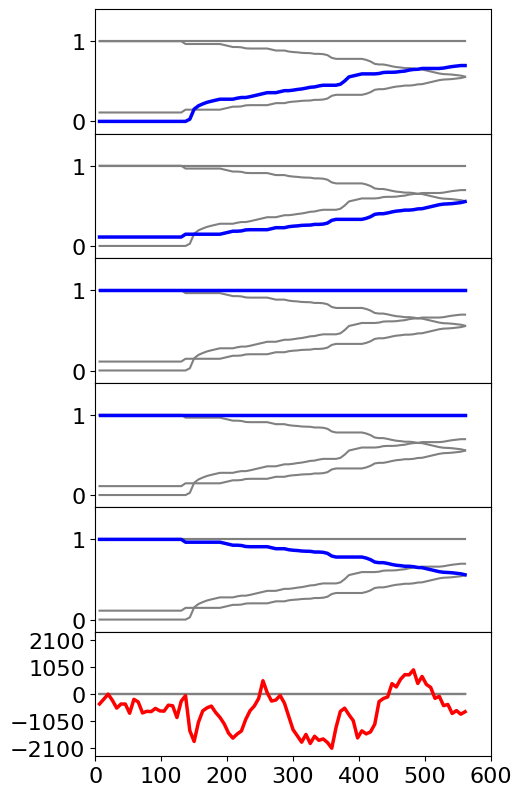

In [45]:

directory = "sequence_data"
show_name = "gFHR_random_7"
name = "Random Sequence"


for file_name in ["gFHR_automated10", "gFHR_automated11"]:

    input_df = add_computed_features(pd.read_csv(f"{directory}/{file_name}_inputs.csv.gz", index_col=0))
    output_df = add_computed_targets(pd.read_csv(f"{directory}/{file_name}_outputs.csv.gz", index_col=0))
    
    
    # Preparation of variables
    time = input_df["cumulative_time"] 
    power = input_df["power"]/280e6
    fuel_insertion_fraction = 1-input_df["graphite_insertion_fraction"]
    discard_threshold = input_df["fima_discharge_threshold"]/18.63
    circulation_rate = 6.525/input_df["burnup_step"]
    control_rod_insertion = (369.47-input_df["control_rod_position"])/309.47
    
    num_discarded = input_df["num_discarded"]/max(input_df["num_discarded"])
    
    avg_power_per_pebble = input_df["average_power_per_pebble"]/max(input_df["average_power_per_pebble"])
    
    
    output_df_std, _, _ = standardize(output_df, target_mean, target_std)
    

    reactivity = output_df["reactivity"]*1e5 #/max(np.abs(output_df["reactivity"]))
    discharge_burnup = input_df["avg_FIMA"]/max(input_df["avg_FIMA"])
    center_last_pass_fima = input_df["R1_avg_FIMA_last_pass"]/max(input_df["R1_avg_FIMA_last_pass"])

    
    plt.rcParams.update({
        "figure.facecolor":  (1.0, 1.0, 1.0, 0.0),  # red   with alpha = 30%
        "axes.facecolor":    (1.0, 1.0, 1.0, 1),  # green with alpha = 50%
        "figure.autolayout": False
    })
    
    
    parameter_color_scheme = {
        "input": "blue",
        "dependent_input": "green",
        "output": "red"
    }
    
    
    input_variables_structure = {
        "Power": (power, "input"),
        "Fuel Insertion Fraction": (fuel_insertion_fraction, "input"),
        "Fuel Circulation Rate": (circulation_rate, "input"),
        "Burnup Discard Threshold": (discard_threshold, "input"),
        "Control Rod Insertion": (control_rod_insertion, "input"),
        "Reactivity (pcm)": (reactivity, "output"),
    }
    


    print(file_name)
    if show_name == file_name:
        b_show = True
    else:
        b_show = False
    make_good_spaghetti_plot_automation(input_variables_structure, file_name+"_inputs_startup", b_show=b_show, unnormalize_reactivity=True, b_do_time=True)
    make_good_spaghetti_plot_automation(input_variables_structure, file_name+"_inputs_startup_unlabeled", b_show=b_show, unnormalize_reactivity=True, 
                                        b_do_time=True, show_control_labels=False)
  

In [58]:
np.max(np.abs(reactivity))

0.3600279621749023

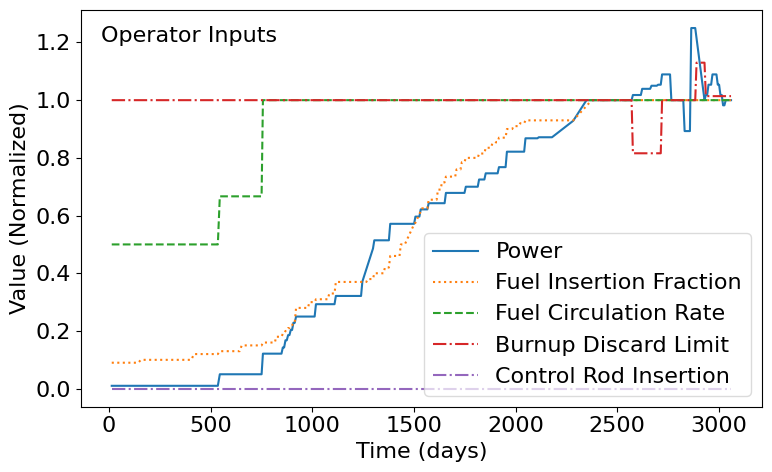

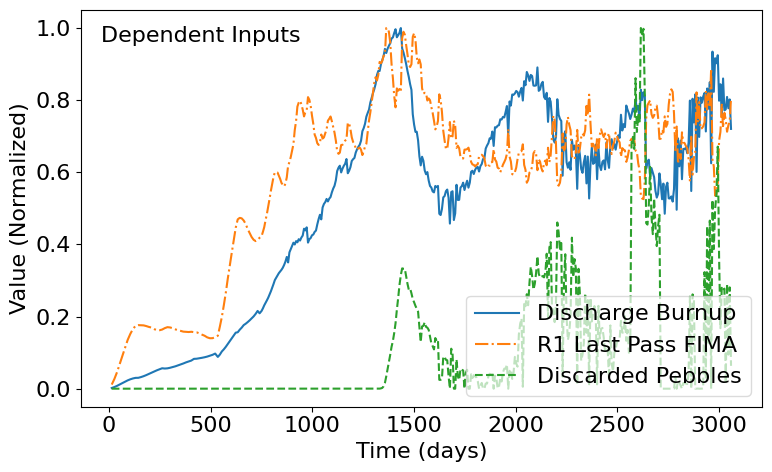

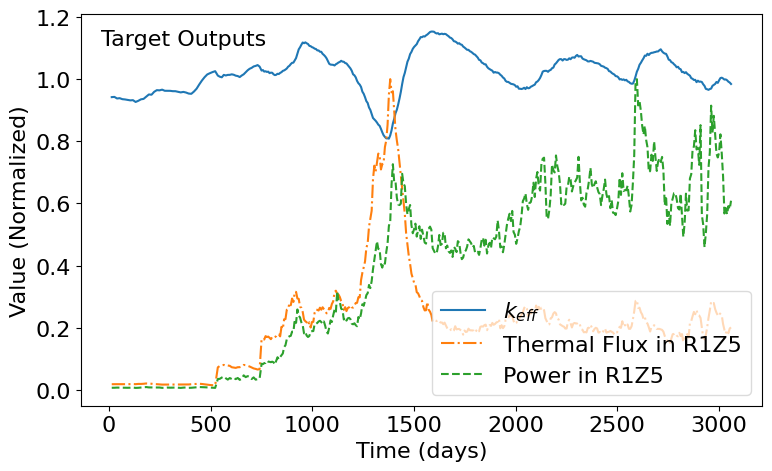

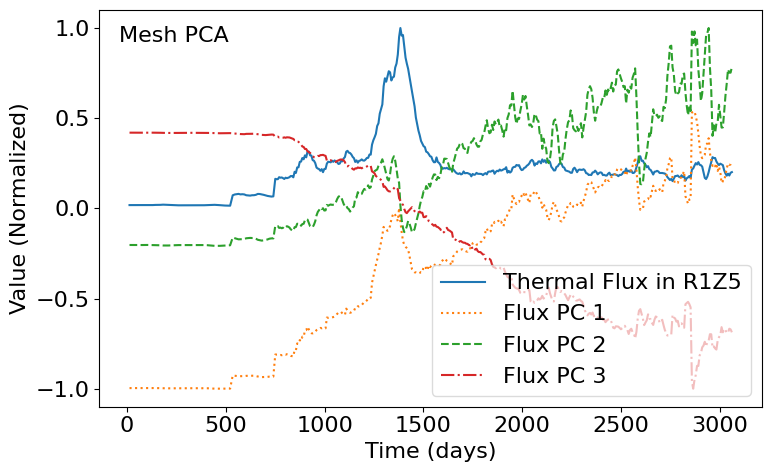

In [56]:
directory = "sequence_data"
file_name = "gFHR_sequence10"
name = "Sequence 1"

input_df = pd.read_csv(f"{directory}/{file_name}_inputs.csv.gz", index_col=0)
output_df = pd.read_csv(f"{directory}/{file_name}_outputs.csv.gz", index_col=0)

time = input_df["cumulative_time"] 
power = input_df["power"]/280e6
fuel_insertion_fraction = 1-input_df["graphite_insertion_fraction"]
discard_threshold = input_df["fima_discharge_threshold"]/18.63
circulation_rate = 6.525/input_df["burnup_step"]
control_rod_insertion = (369.47-input_df["control_rod_position"])/309.47

num_discarded = input_df["num_discarded"]/max(input_df["num_discarded"])

output_df_std, _, _ = standardize(output_df, target_mean, target_std)

keff = output_df["final_analog_keff"]
discharge_burnup = input_df["avg_FIMA"]/max(input_df["avg_FIMA"])
center_last_pass_fima = input_df["R1_avg_FIMA_last_pass"]/max(input_df["R1_avg_FIMA_last_pass"])
flux_pca_vals = flux_pca.transform(output_df_std[flux_columns])
power_pca_vals = power_pca.transform(output_df_std[power_columns])

flux_pca_1 = flux_pca_vals[:,0] / max(np.abs(flux_pca_vals[:,0]))
flux_pca_2 = flux_pca_vals[:,1] / max(np.abs(flux_pca_vals[:,1]))
flux_pca_3 = flux_pca_vals[:,2] / max(np.abs(flux_pca_vals[:,2]))
flux_pca_4 = flux_pca_vals[:,3] / max(np.abs(flux_pca_vals[:,3]))
flux_pca_5 = flux_pca_vals[:,4] / max(np.abs(flux_pca_vals[:,4]))
power_pca_1 = power_pca_vals[:,0] / max(np.abs(power_pca_vals[:,0]))


thermal_flux_middle = output_df["fluxR1Z5E1"]/max(output_df["fluxR1Z5E1"])
power_middle = output_df["powerR1Z5"]/max(output_df["powerR1Z5"])
fast_flux_lower_corner = output_df["fluxR4Z1E3"]/max(output_df["fluxR4Z1E3"])

compare_parameter = "final_analog_keff"

plt.rcParams.update({
    "figure.facecolor":  (1.0, 1.0, 1.0, 0.0),  # red   with alpha = 30%
    "axes.facecolor":    (1.0, 1.0, 1.0, 1),  # green with alpha = 50%
    "figure.autolayout": True
})

fig, ax = plt.subplots(figsize=(8,5) )
plt.ylabel("Value (Normalized)")
plt.xlabel("Time (days)")
plt.plot(time, power, label="Power")
plt.plot(time, fuel_insertion_fraction, label="Fuel Insertion Fraction", linestyle="dotted")
plt.plot(time, circulation_rate, label="Fuel Circulation Rate", linestyle="dashed")
plt.plot(time, discard_threshold, label="Burnup Discard Limit", linestyle="dashdot")
plt.plot(time, control_rod_insertion, label="Control Rod Insertion", linestyle="dashdot")
plt.legend(framealpha=0.7, loc="lower right")
plt.savefig(f"figures/{file_name}_inputs.png",dpi=600)
plt.text(0.03, 0.96, 'Operator Inputs', ha='left', verticalalignment='top', transform = ax.transAxes)
plt.show()

fig, ax = plt.subplots(figsize=(8,5) )
plt.ylabel("Value (Normalized)")
plt.xlabel("Time (days)")
plt.plot(time, discharge_burnup, label=r"Discharge Burnup")
plt.plot(time, center_last_pass_fima, label="R1 Last Pass FIMA", linestyle="dashdot")
plt.plot(time, num_discarded, label="Discarded Pebbles", linestyle="dashed")
plt.legend(framealpha=0.7, loc="lower right")
plt.savefig(f"figures/{file_name}_outputs.png",dpi=600)
plt.text(0.03, 0.96, 'Dependent Inputs', ha='left', verticalalignment='top', transform = ax.transAxes)
plt.show()

fig, ax = plt.subplots(figsize=(8,5) )
plt.ylabel("Value (Normalized)")
plt.xlabel("Time (days)")
plt.plot(time, keff, label=r"$k_{eff}$")
#plt.plot(time[10:], discharge_burnup[:-10], label=r"Discharge Burnup (Lagging)", linestyle="dotted")
#plt.plot(time, flux_pca_1, label="Flux PC 1", linestyle="dashdot")
plt.plot(time, thermal_flux_middle, label="Thermal Flux in R1Z5", linestyle="dashdot")
#plt.plot(time, power_pca_1, label="Power PC 1", linestyle="dashed")
plt.plot(time, power_middle, label="Power in R1Z5", linestyle="dashed")
plt.legend(framealpha=0.7, loc="lower right")
plt.savefig(f"figures/{file_name}_outputs.png",dpi=600)
plt.text(0.03, 0.96, 'Target Outputs', ha='left', verticalalignment='top', transform = ax.transAxes)
plt.show()


fig, ax = plt.subplots(figsize=(8,5) )
plt.ylabel("Value (Normalized)")
plt.xlabel("Time (days)")


plt.plot(time, thermal_flux_middle, label=r"Thermal Flux in R1Z5")
#plt.plot(time, fast_flux_lower_corner, label=r"Fast Flux in R4Z1")
plt.text(0.03, 0.96, 'Mesh PCA', ha='left', verticalalignment='top', transform = ax.transAxes)
plt.plot(time, flux_pca_1, label="Flux PC 1", linestyle="dotted")
plt.plot(time, flux_pca_2, label="Flux PC 2", linestyle="dashed")
plt.plot(time, flux_pca_3, label="Flux PC 3", linestyle="dashdot")
plt.legend(framealpha=0.7, loc="lower right")
plt.savefig(f"figures/{file_name}_outputs.png",dpi=600)
plt.show()




In [ ]:
input_variables_structure = {
    "Power": (power, "input"),
    "Fuel Insertion Fraction": (fuel_insertion_fraction, "input"),
    "Fuel Circulation Rate": (circulation_rate, "input"),
    "Burnup Discard Threshold": (discard_threshold, "input"),
    "Control Rod Insertion": (control_rod_insertion, "input"),
    "Avg. Discharge Burnup": (discharge_burnup, "dependent_input"),
    "# Discarded Pebbles": (num_discarded, "dependent_input"),
    "R1 Last Pass FIMA": (center_last_pass_fima, "dependent_input")
}

output_variables_structure = {
    "Power": (power, "input"),
    "Fuel Insertion Fraction": (fuel_insertion_fraction, "input"),
    "Avg. Discharge Burnup": (discharge_burnup, "dependent_input"),
    r"$k_{eff}$": (keff, "output"),
    "Flux PC 1": (flux_pca_1, "output"),
    "Flux PC 2": (flux_pca_2, "output"),
    "Power PC 1": (power_pca_1, "output"),
    "Power PC 2": (power_pca_2, "output"),
}

In [165]:
input_df["graphite_insertion_fraction"].iloc[240]

0.75

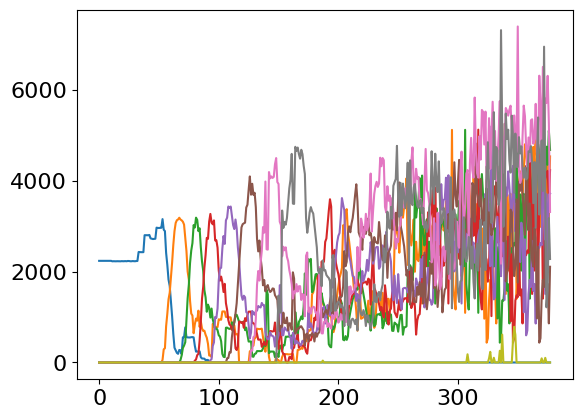

In [46]:
plt.figure()
plt.plot(input_df.index, input_df[bin_columns])

plt.show()

In [64]:
input_df

,power,burnup_step,graphite_insertion_fraction,control_rod_position,fima_discharge_threshold,fima_discharge_rel_std,R1_avg_FIMA_last_pass,R2_avg_FIMA_last_pass,R3_avg_FIMA_last_pass,R4_avg_FIMA_last_pass,...,burnup_bin3_count,burnup_bin4_count,burnup_bin5_count,burnup_bin6_count,burnup_bin7_count,burnup_bin8_count,burnup_bin9_count,avg_FIMA,num_discarded,cumulative_time
0,1000000.0,3.425,0.91,369.47,18.63,0.02288,0.004022,0.003197,0.002591,0.002102,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.002991,0.0,3.425
1,1000000.0,3.425,0.91,369.47,18.63,0.02288,0.009547,0.007707,0.006183,0.005094,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007163,0.0,6.850
2,1000000.0,3.425,0.91,369.47,18.63,0.02288,0.016207,0.013194,0.010548,0.008727,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.012221,0.0,10.275
3,1000000.0,3.425,0.91,369.47,18.63,0.02288,0.024028,0.019388,0.015550,0.012732,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.018003,0.0,13.700
4,1000000.0,3.425,0.91,369.47,18.63,0.02288,0.031890,0.025799,0.020754,0.017144,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.023999,0.0,17.125
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
373,280000000.0,6.525,0.00,369.47,18.63,0.02288,2.361112,2.088876,1.879964,2.062389,...,4168.0,4014.0,1509.0,2679.0,5813.0,3705.0,102.0,11.641084,2394.0,2476.225
374,280000000.0,6.525,0.00,369.47,18.63,0.02288,2.670902,2.358156,2.125731,2.323854,...,4752.0,4164.0,3706.0,1574.0,5717.0,1215.0,0.0,10.405941,373.0,2482.750
375,280000000.0,6.525,0.00,369.47,18.63,0.02288,2.811557,2.483279,2.231876,2.434985,...,4354.0,4221.0,2022.0,1729.0,6312.0,1587.0,0.0,10.516410,288.0,2489.275
376,280000000.0,6.525,0.00,369.47,18.63,0.02288,2.791993,2.470969,2.209454,2.414617,...,5107.0,3624.0,3694.0,861.0,5265.0,3180.0,0.0,11.112378,1161.0,2495.800


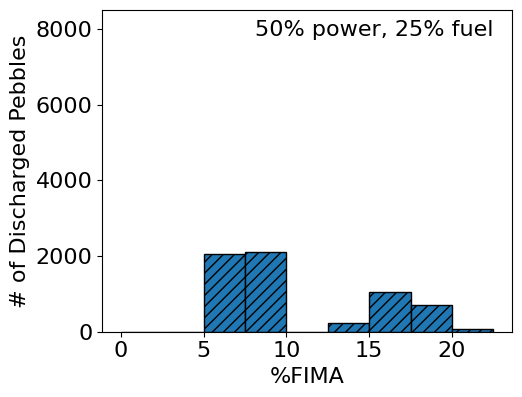

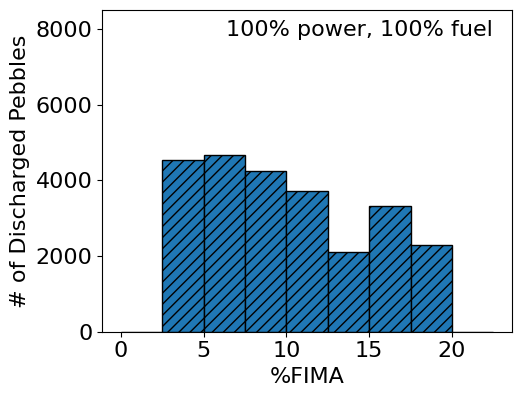

In [65]:
directory = "sequence_data"
file_name = "gFHR_sequence"

input_df = pd.read_csv(f"{directory}/{file_name}_inputs.csv.gz", index_col=0)

bin_columns = []
for i in range(1,1+9):
    bin_columns += [f"burnup_bin{i}_count"]
bin_counts = input_df[bin_columns].iloc[240]

bin_edges = np.linspace(0,22.5,10)

plt.figure(figsize=(5.5,4.25) )
plt.text(22.5, 7800, "50% power, 25% fuel", ha="right")
plt.ylim(0,8500)
plt.hist(bin_edges[:-1], bins=bin_edges, weights=bin_counts, hatch="///", edgecolor="black")
plt.xlabel("%FIMA")
plt.ylabel("# of Discharged Pebbles")
plt.tight_layout()
plt.savefig("figures/low_power_BU_distribution")
plt.show()

directory = "sequence_data"
file_name = "gFHR_sequence11"

input_df = pd.read_csv(f"{directory}/{file_name}_inputs.csv.gz", index_col=0)

bin_columns = []
for i in range(1,1+9):
    bin_columns += [f"burnup_bin{i}_count"]
bin_counts = input_df[bin_columns].iloc[-1]

bin_edges = np.linspace(0,22.5,10)

plt.figure(figsize=(5.5,4.25) )
plt.text(22.5, 7800, "100% power, 100% fuel", ha="right")
plt.ylim(0,8500)
plt.hist(bin_edges[:-1], bins=bin_edges, weights=bin_counts, hatch="///", edgecolor="black")
plt.xlabel("%FIMA")
plt.ylabel("# of Discharged Pebbles")
plt.tight_layout()
plt.savefig("figures/high_power_BU_distribution")
plt.show()

## Mesh Plotting

/tmp/ipykernel_945338/400539627.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  point_powers[r_ind,z_ind] = meshes["subzone_power"]["data"][r_bin,z_bin]


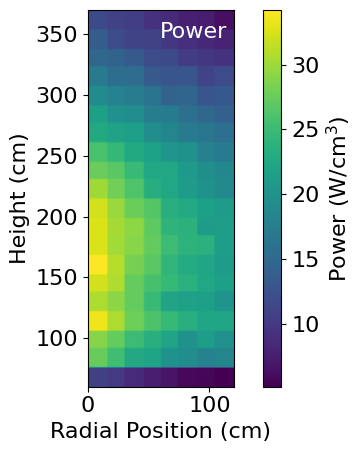

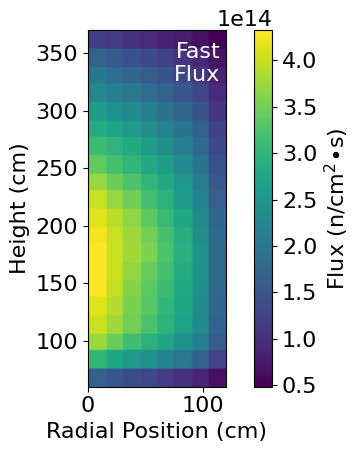

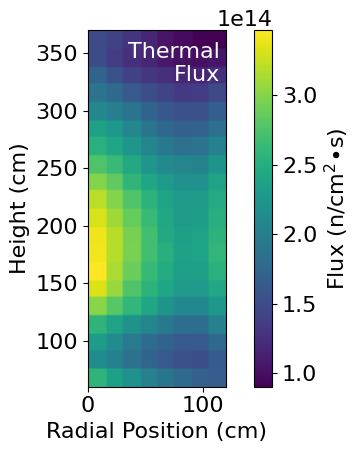

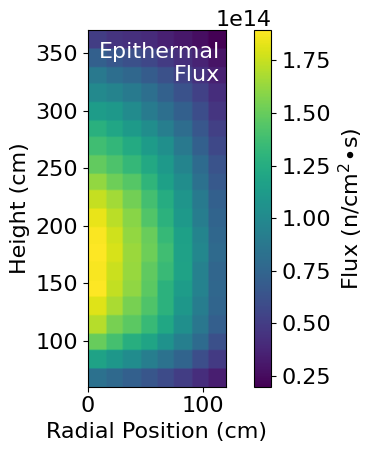

In [9]:
from pearlsim.group_definitions import *
from pearlsim.ml_utilities import *
plt.rcParams.update({'font.size': 16})
from pearlsim.results_processing import read_core_flux
def plot_mesh_data(step, substep, directory = "gFHR_sequence", points_per_cm=0.5):

    current_energy_widths = np.diff(ENERGY_GRID_56)
    det_name = f"gFHR_equilibrium_{step}.serpent_det{substep}.m"
    meshes = read_det_file(f"{directory}/{det_name}", 
                            read_pebbles=False,
                            meshes_to_read=["subzone_3group_flux",
                                            "subzone_power"], 
                            mesh_grids_rze = [(RADIUS_GRID_8, HEIGHT_GRID_20, ENERGY_GRID_3),
                                              (RADIUS_GRID_8, HEIGHT_GRID_20, [0,20]) ] )
    radius_grid = RADIUS_GRID_8
    height_grid = HEIGHT_GRID_20
    min_r = np.min(radius_grid)
    max_r = np.max(radius_grid)
    r_bins = len(radius_grid)-1
    min_z = np.min(height_grid)
    max_z = np.max(height_grid)
    z_bins = len(height_grid)-1

    
    num_r_points = int((max_r-min_r)*points_per_cm)
    num_z_points = int((max_z-min_z)*points_per_cm)
    r_array = np.linspace(0+1e-6,120-1e-6, num_r_points)
    z_array = np.linspace(min_z+1e-6,max_z-1e-6,num_z_points)
    r_bin_bounds = np.linspace(min_r,max_r,r_bins+1)
    z_bin_bounds = np.linspace(min_z,max_z,z_bins+1)
    
    point_powers = np.zeros([num_r_points,num_z_points])
    point_flux_fast = np.zeros([num_r_points,num_z_points])
    point_flux_thermal = np.zeros([num_r_points,num_z_points])
    point_flux_epithermal = np.zeros([num_r_points,num_z_points])
    
    for r_ind in range(len(r_array)):
        for z_ind in range(len(z_array)):
            r = r_array[r_ind]
            z = z_array[z_ind]
            r_bin = np.searchsorted(r_bin_bounds, r)-1
            z_bin = np.searchsorted(z_bin_bounds, z)-1
            point_powers[r_ind,z_ind] = meshes["subzone_power"]["data"][r_bin,z_bin]
            point_flux_fast[r_ind, z_ind] = meshes["subzone_3group_flux"]["data"][r_bin,z_bin,2]
            point_flux_thermal[r_ind, z_ind] = meshes["subzone_3group_flux"]["data"][r_bin,z_bin,0]
            point_flux_epithermal[r_ind, z_ind] = meshes["subzone_3group_flux"]["data"][r_bin,z_bin,1]

    plt.figure()
    plt.imshow(np.rot90(point_powers,1), extent=(0,120,60,370))#), aspect='auto')
    plt.colorbar(label=r"Power (W/cm$^3$)")
    #plt.title(f"Power Distribution by Subzone")
    plt.xlabel("Radial Position (cm)")
    plt.ylabel("Height (cm)")
    plt.text(115, 360, "Power", ha="right", va="top", color="white")
    plt.tight_layout()
    plt.savefig("figures/example_power_mesh.png")
    plt.show()

    plt.figure()
    plt.imshow(np.rot90(point_flux_fast,1), extent=(0,120,60,370))#, aspect='auto')
    plt.colorbar(label=r"Flux (n/cm$^2$$\bullet$s)")
    #plt.title(f"Power Distribution by Subzone")
    plt.xlabel("Radial Position (cm)")
    plt.ylabel("Height (cm)")
    plt.text(115, 360, "Fast\nFlux", ha="right", va="top", color="white")
    plt.tight_layout()
    plt.savefig("figures/example_fast_flux_mesh.png")
    plt.show()

    plt.figure()
    plt.imshow(np.rot90(point_flux_thermal,1), extent=(0,120,60,370))#, aspect='auto')
    plt.colorbar(label=r"Flux (n/cm$^2$$\bullet$s)")
    #plt.title(f"Power Distribution by Subzone")
    plt.xlabel("Radial Position (cm)")
    plt.ylabel("Height (cm)")
    plt.text(115, 360, "Thermal\nFlux", ha="right", va="top", color="white")
    plt.tight_layout()
    plt.savefig("figures/example_thermal_flux_mesh.png")
    plt.show()

    plt.figure()
    plt.imshow(np.rot90(point_flux_epithermal,1), extent=(0,120,60,370))#, aspect='auto')
    plt.colorbar(label=r"Flux (n/cm$^2$$\bullet$s)")
    #plt.title(f"Power Distribution by Subzone")
    plt.xlabel("Radial Position (cm)")
    plt.ylabel("Height (cm)")
    plt.text(115, 360, "Epithermal\nFlux", ha="right", va="top", color="white")
    plt.tight_layout()
    plt.savefig("figures/example_epithermal_flux_mesh.png")
    plt.show()



    return 
plot_mesh_data(400,2)

# LEGACY

In [ ]:
train_len, dim1, dim2 = training_data.shape
test_len, _, _ = testing_data.shape

# Define LSTM model
keff_model = tf.keras.Sequential([
    tf.keras.Input((dim1, dim2)),
    tf.keras.layers.LSTM(128),
    tf.keras.layers.Dense(1, activation="linear")
])

epochs = 500
batch_size = 1024
learning_rate = 0.001

# Compile model
keff_model.compile(loss='mse', optimizer='adam')

# Train model
X_train = training_data_std
y_train = training_target_std["final_analog_keff"].to_numpy().reshape([train_len, 1])

X_test = testing_data_std
y_test = testing_target_std["final_analog_keff"].to_numpy().reshape([test_len, 1])
keff_model.fit(X_train, y_train, 
               epochs=epochs, 
               batch_size=batch_size, 
               verbose=1, 
               validation_data=(X_test, y_test))

y_test_pred = keff_model.predict(X_test)
r2_score_seen_sequences = r2_score(y_test_pred, y_test)
print(f"r2 score: {r2_score_seen_sequences}")

In [ ]:
def prepare_sequence(features, targets, window):
    length, num_features = features.shape
    _, num_targets = targets.shape
    num_data = length-1
    num_samples = num_data - window
    feature_list = []
    target_list = []
    for index in np.arange(window, num_data):
        feature_list += [features.iloc[index-window:index].to_numpy().reshape(1, window, num_features)]
        target_list += [pd.concat([targets.iloc[index], features.iloc[index+1].drop(columns=control_feature_labels)])]
    return np.concatenate(feature_list, axis=0), pd.DataFrame(target_list)

In [ ]:
fit_test_input_std, _, _ = standardize(fit_test_input, mean=data_mean, std=data_std, axis=2)
generalize_test_input_std, _, _ = standardize(geneneralize_test_input, mean=data_mean, std=data_std, axis=2)

fit_test_output_std, _, _ = standardize(fit_test_output, mean=target_mean, std=target_std, axis=0)
generalize_test_output_std, _, _ = standardize(generalize_test_output, mean=target_mean, std=target_std, axis=0)

fit_test_len, dim1, dim2 = fit_test_input_std.shape

# Train model
X_fit_test = fit_test_input_std
y_fit_test = fit_test_output_std["final_analog_keff"].to_numpy().reshape([fit_test_len, 1])


y_fit_test_predict_std = keff_model.predict(X_fit_test)


gen_test_len, dim1, dim2 = generalize_test_input_std.shape

# Train model
X_gen_test = generalize_test_input_std
y_gen_test = generalize_test_output_std["final_analog_keff"].to_numpy().reshape([gen_test_len, 1])


y_gen_test_predict_std = keff_model.predict(X_gen_test)

In [ ]:
output_parameters = {
    "reactivity": "reactivity",
    "power_pca0": "Power PC 1",
    "flux_pca0": "Flux PC 1",}

for parameter_key in output_parameters.keys():
    compare_parameter = parameter_key
    parameter_label = output_parameters[parameter_key]
    plt.rcParams.update({
        "figure.facecolor":  (1.0, 1.0, 1.0, 0.0),  # red   with alpha = 30%
        "axes.facecolor":    (1.0, 1.0, 1.0, 1),  # green with alpha = 50%
        "figure.autolayout": True
    })

    
    plt.figure()
    plt.title("LSTM performance on seen sequence (80-20 split)")
    plt.xlabel("Simulation Time (days)")
    plt.ylabel(f"{parameter_label} Value")
    plt.plot(fit_test_input_time, fit_test_output_df[compare_parameter], label="Actual")
    plt.plot(fit_test_input_time[window_length:-1], y_fit_test_predict[compare_parameter], label="Predicted")
    print(f"r2 score: {r2_score(fit_test_output_df[compare_parameter].iloc[window_length:-1], y_fit_test_predict[compare_parameter])}")
    plt.legend(framealpha=1)
    plt.savefig(f"figures/lstm_{compare_parameter}_seen.png",dpi=600)
    plt.show()
    

    
    plt.figure()
    plt.title("LSTM performance on brand new sequence")
    plt.xlabel("Simulation Time (days)")
    plt.ylabel(f"{parameter_label} Value")
    plt.plot(gen_test_input_time, generalize_test_output_df[compare_parameter], label="Actual")
    plt.plot(gen_test_input_time[window_length:-1], y_gen_test_predict[compare_parameter], label="Predicted")
    print(f"r2 score: {r2_score(generalize_test_output_df[compare_parameter].iloc[window_length:-1], y_gen_test_predict[compare_parameter])}")
    plt.legend(framealpha=1)
    plt.savefig(f"figures/lstm_{compare_parameter}_unseen.png", dpi=600)
    plt.show()

In [ ]:
directory = "sequence_data"

forecast_sequences = {"gFHR_forecast_power_up":"Power Increase",
                     "gFHR_forecast_power_down":"Power Decrease",
                     "gFHR_forecast_graphite_up":"Fuel Insertion Ratio Decrease",
                     "gFHR_forecast_circulation_slower":"Slower Pebble Circulation",
                     "gFHR_forecast_rods_in":"Rod Insertion",
                     "gFHR_forecast_threshold_down":"Fuel Discard Burnup Threshold Decrease"}
#fit_test_sequence = "gFHR_forecast_base"
#generalize_test_sequence = "gFHR_sequence7"

for sequence_name in forecast_sequences.keys():
    title = forecast_sequences[sequence_name]
    
    
    forecast_input_df = add_computed_features( pd.read_csv(f"{directory}/{sequence_name}_inputs.csv.gz", index_col=0)).drop(columns=["fima_discharge_rel_std"])
    forecast_input_time = forecast_input_df["cumulative_time"]
    forecast_input_df = forecast_input_df.drop(columns=["cumulative_time"])
    forecast_output_df = add_computed_targets( pd.read_csv(f"{directory}/{sequence_name}_outputs.csv.gz", index_col=0))

    history_keff_predicted = lstm.predict(forecast_input_df[-61:-20], predict_labels)["reactivity"]
    history_keff_actual = forecast_output_df[-40:-20]["reactivity"]
    
    #y_fit_test_predict = lstm.predict(forecast_input_df, predict_labels)
    forecast_slice = forecast_input_df[-39:-19].to_numpy().reshape(1, 20, len(forecast_input_df.columns))
    forecasted_keff_predicted = lstm.forecast(forecast_slice, 20, dependent_input_labels, predict_labels=["reactivity"])["reactivity"]*target_std["reactivity"]+target_mean["reactivity"]
    forecasted_keff_actual =  forecast_output_df[-20:]["reactivity"]

    plt.figure()
    timestep = np.arange(40)
    plt.plot(timestep, pd.concat([history_keff_actual, forecasted_keff_actual]), linestyle="dashed", label="Serpent Simulated")
    plt.plot(timestep, pd.concat([history_keff_predicted, forecasted_keff_predicted]), label="LSTM-Predicted")
    ymin = np.min( pd.concat([history_keff_actual, forecasted_keff_actual, 
                              history_keff_predicted, forecasted_keff_predicted]))
                  
    ymax = np.max( pd.concat([history_keff_actual, forecasted_keff_actual, 
                              history_keff_predicted, forecasted_keff_predicted]))
    plt.legend()
    #plt.title(title)
    plt.text(40, ymin, title, ha="right")
    plt.xlabel("Timestep")
    plt.ylabel("Reactivity")
    plt.vlines(20, ymin, ymax)
    plt.show()
    plt.savefig(f"figures/forecasting/{sequence_name}.png")

    #fit_test_input, fit_test_output = prepare_sequence(fit_test_input_df, fit_test_output_df, window_length)
    #geneneralize_test_input, generalize_test_output = prepare_sequence(generalize_test_input_df, generalize_test_output_df, window_length)
    

In [ ]:
directory = "sequence_data"

forecast_sequences = {"gFHR_forecast_power_up":"Power Increase",
                     "gFHR_forecast_power_down":"Power Decrease",
                     "gFHR_forecast_graphite_up":"Fuel Insertion Ratio Decrease",
                     "gFHR_forecast_circulation_slower":"Slower Pebble Circulation",
                     "gFHR_forecast_rods_in":"Rod Insertion",
                     "gFHR_forecast_threshold_down":"Fuel Discard Burnup Threshold Decrease"}
#fit_test_sequence = "gFHR_forecast_base"
#generalize_test_sequence = "gFHR_sequence7"

forecast_length = window_length*2
forecast_edge = -forecast_length-1-window_length

first_plot = True

for sequence_name in forecast_sequences.keys():
    title = forecast_sequences[sequence_name]
    
    
    forecast_input_df = add_computed_features( pd.read_csv(f"{directory}/{sequence_name}_inputs.csv.gz", index_col=0)).drop(columns=["fima_discharge_rel_std"])
    forecast_input_time = forecast_input_df["cumulative_time"]
    forecast_input_df = forecast_input_df.drop(columns=["cumulative_time"])
    forecast_output_df = add_computed_targets( pd.read_csv(f"{directory}/{sequence_name}_outputs.csv.gz", index_col=0))

    history_keff_predicted = lstm.predict(forecast_input_df[-forecast_edge:-window_length], predict_labels)["reactivity"]
    history_keff_actual = forecast_output_df[-40:-window_length]["reactivity"]
    
    #y_fit_test_predict = lstm.predict(forecast_input_df, predict_labels)
    edge = -window_length+1
    forecast_slice = forecast_input_df[-39:edge].to_numpy().reshape(1, window_length, len(forecast_input_df.columns))
    forecasted_keff_predicted = lstm.forecast(forecast_slice, window_length, dependent_input_labels, predict_labels=["reactivity"])["reactivity"]*target_std["reactivity"]+target_mean["reactivity"]
    forecasted_keff_actual =  forecast_output_df[-window_length:]["reactivity"]

    plt.figure()
    timestep = np.arange(40)
    plt.plot(timestep, pd.concat([history_keff_actual, forecasted_keff_actual]), linestyle="dashed", label="Serpent Simulated")
    plt.plot(timestep, pd.concat([history_keff_predicted, forecasted_keff_predicted]), label="LSTM-Predicted")
    ymin = np.min( pd.concat([history_keff_actual, forecasted_keff_actual, 
                              history_keff_predicted, forecasted_keff_predicted]))
                  
    ymax = np.max( pd.concat([history_keff_actual, forecasted_keff_actual, 
                              history_keff_predicted, forecasted_keff_predicted]))
    if first_plot:
        plt.legend(loc="upper right")
        first_plot = False
    #plt.title(title)
    plt.text(40, ymin, title, ha="right")
    plt.xlabel("Timestep")
    plt.ylabel("Reactivity")
    plt.vlines(20, ymin, ymax)
    plt.show()
    plt.savefig(f"figures/forecasting/{sequence_name}.png")

    #fit_test_input, fit_test_output = prepare_sequence(fit_test_input_df, fit_test_output_df, window_length)
    #geneneralize_test_input, generalize_test_output = prepare_sequence(generalize_test_input_df, generalize_test_output_df, window_length)
    